# OPERA Advanced Interactive Activities (AIA) Set 1 — Workshop
---
## Day 1: EEOFS Activation & CMEMS Data Access

**Content creator:** Babette C. Tchonang

**Content editors:**

**Production editors**

**Content coordinator**: Arielle Stella Imbol

## About This MOOC

This tutorial is part of the **OPERA Capacity Development**, developed and led jointly by **GGOSSS** and **ICMPA - UNESCO CHAIR** .

The OPERA project is **financed by the European Union** and implemented by **Mercator Ocean International**, in the framework of the **Ocean Prediction Decade Collaborative Centre (OceanPrediction DCC)**.

> *Funded by the European Union. Views and opinions expressed are however those of the author(s) only and do not necessarily reflect those of the European Union. The European Union cannot be held responsible for them.*

---

### Day 1 Schedule (09:00–18:00)

| Time | Format | Activity | Notebook |
|------|--------|----------|----------|
| 09:00–09:15 | Opening Plenary | Coordinator welcome, housekeeping, team introductions | — |
| 09:15–10:45 | Subgroups | **Setup** — Drive, packages, environment working for everyone | Section 0 |
| 10:45–11:05 | Break | | |
| 11:05–11:50 | Opening Plenary | Expert Tutorial — **EEOFS Activation** (35 min + 10 min Q&A) | Section 1 |
| 11:50–12:10 | Opening Plenary | Study region and the map | Section 2 |
| 12:10–12:30 | Subgroups | CMEMS account and authentication | Section 3 |
| 12:30–13:30 | Lunch | | |
| 13:30–15:00 | Plenary + Subgroups | Expert Demonstration — **four datasets, two services** (CMEMS and CDS) | Section 4 |
| 15:00–15:20 | Break | | |
| 15:20–16:20 | Subgroups | Guided Practice — opening NetCDF, inspecting what is inside | Section 5 |
| 16:20–17:20 | Subgroups | **Independent work** — your own maps and time series | Sections 6–7 |
| 17:20–17:50 | Reconvergence Plenary | **First Maps Gallery Walk** | Discussion |
| 17:50–18:00 | Wrap-Up Plenary | Day 1 Reflection & Day 2 Preview | Sections 8–9 |

> **Note on timing:** the download block (13:30–15:00) covers four datasets from **two different services** — CMEMS for the ocean, CDS/ERA5 for the atmosphere. The ERA5 portion is allocated more time because it needs a second account and its requests are queued.
>
> **Facilitators:** every section header repeats its slot, so you can see at a glance whether the room is running ahead or behind. If you are behind by 15:00, shorten the Inspection block rather than Independent Work — people learn more from doing than from watching.

---

###  Day 1 Learning Objectives

1. Rapidly reconnect validated MOOC knowledge (EEOFS, virtuous loop) to practical CMEMS workflows — **activation, not re-teaching**
2. Navigate the CMEMS portal to search, preview, and download SSH, SST, and ocean current products
3. Understand CMEMS product families: observations, reanalysis, forecasts, and hindcasts
4. Download datasets programmatically via the `copernicusmarine` Python API
5. Open and inspect downloaded NetCDF files in Python using `xarray`

---

###  How This Notebook Works

| |  Lead Instructor |  Participant |
|---|---|---|
| **Section 0** | Run — sets up Drive + packages | Run — same setup steps |
| **Section 3 (Login)** | ==> Run during plenary demo |  Study — do NOT run today |
| **Section 4 (Downloads)** | ==> Run — saves data to shared Drive |  Study — do NOT run today |
| **Sections 1, 2, 5, 6, 7, 8, 9** | ==> Run and demonstrate live | ==> Run during subgroup practice |

> **Prerequisite:** Workshop is reserved for MOOC Set 1 graduates with ≥70% overall score.  
> We do not re-teach MOOC content — we *activate* it and *apply* it to real data.

---

---



---

##  What changed in this version

This notebook was revised from the original Day 1. If you have seen the earlier version, these are the differences.

### Structure

| Change | Where | Why |
|--------|-------|-----|
| **Two phases** — `PHASE = 'shared'` / `'zone'` | Config cell | Everyone works the full Gulf of Guinea today; subgroups narrow to their own area on Days 2–3. One line switches. |
| **Three study areas** replace subgroups A/B/C | Config cell | The old areas were three slices of one coast. These are an eastern boundary upwelling system, an equatorial system and a western boundary current — a real comparison at the plenary. |
| **Time slot on every section** | All headers | See at a glance whether the room is running ahead or behind. |

### Data

| Change | Where | Why |
|--------|-------|-----|
| **Fourth dataset: wind** | 4.4 | Wind is the *forcing*; the other three are the ocean's response. Closes the loop to Module 2. |
| **Wind comes from ERA5, not CMEMS** | 4.4 | Teaches a second data ecosystem — different client, credentials, bounding-box syntax, and a queue. `WIND_SOURCE = 'CMEMS'` switches back. |
| **Resumable full-record download** | 4.5 | One file per year. An interruption costs one year, not everything. |
| **Drive inventory before downloading** | 4.0b | Opens every file found and reports whether it is usable, so you know what will happen before you run anything. |
| **Downloads verify, not just check existence** | 4.1–4.4 | A truncated file passes `os.path.exists()` and fails days later. Complete files are skipped; unusable ones are replaced. |
| **Universal loader** | Section 5 | `open_product()` reads staged single files or self-downloaded year-files identically, so nobody is stranded on Day 2. |
| **Readiness check opens the data** | 4.6 | Verifies variables, time span and bounding box rather than filenames. |

### Fixes

| Fixed | Was |
|-------|-----|
| `force_download` removed from all downloads | Removed in `copernicusmarine` v2 — would have raised `TypeError` on every call |
| Login checks before prompting | Prompted every time, even when already authenticated |
| SST colour scale follows the area | Hardcoded 26–29 °C — the Agulhas would have rendered nearly uniform |
| Map legend matches what is plotted | Labelled three coastal reference points as the three study areas |
| Gridlines follow the domain | Hardcoded to the Gulf of Guinea range |
| Southern-hemisphere warning | Nothing flagged that JJA is winter in the Agulhas |
| Schedule times reconcile | Sections 8 and 9 both claimed 16:45–17:00; 10:30–14:00 was unaccounted for |

> **Not changed:** the science, the section order, and the teaching arc. This is the same Day 1 — parameterised, verified, and with the forcing added.

---


---

##  Section 0 — Google Colab & Environment Setup

*Setup Block  |  09:15–10:45  (90 min — everyone, hands on)*


*Run before anything else — instructor and participants alike.*

### Why Google Colab + Google Drive?

Google Colab gives everyone a free Python environment with GPU/CPU access — no local installation needed.  
The one limitation: **Colab sessions reset after ~90 minutes of inactivity**, deleting all locally saved files.

**The solution:** save all downloaded data directly to your **Google Drive**.  
Files saved to Drive persist permanently across all 3 days of the workshop and all future professional use.

```
Your Google Drive
└── MyDrive/
    └── OPERA_Workshop_Data/
        └── data/
            ├── GOG_SST_reanalysis.nc     ← shared domain, used all 3 days
            ├── GOG_SSH_altimetry.nc
            ├── GOG_currents.nc
            ├── GOG_wind_monthly.nc       ← atmospheric forcing (ERA5)
            │
            ├── MRS_*.nc                  ← Area 1, Mauritania / Senegal
            ├── AGU_*.nc                  ← Area 3, Agulhas
            │
            └── GOG_daily_years/          ← only if you run section 4.5
                ├── GOG_SST_2010.nc
                └── ...
```

>  **Participants:** Before running Cell 0.1, make sure you have added the instructor's shared  
> folder shortcut to your Drive: open the shared link → right-click `OPERA_Workshop_Data` → *"Add shortcut to My Drive"*

---

In [2]:
# ============================================================
# STEP 0.1 — MOUNT GOOGLE DRIVE  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Connects your Google Drive to this Colab session.
# A browser prompt will appear — click "Connect to Google Drive"
# and authorise with your Google account.
#
# All downloaded files will be saved to Drive and will persist
# across sessions, days, and after the workshop ends.
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os

# Workshop data directory in Google Drive
DATA_DIR = '/content/drive/MyDrive/OPERA_Workshop_Data/data'
os.makedirs(DATA_DIR, exist_ok=True)
OUTPUT_DIR = '/content/drive/MyDrive/OPERA_Workshop_Data/output/Day1'
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('==> Google Drive mounted successfully!')
print()
print(f'   Workshop data directory : {DATA_DIR}')
print()
print(f'   Workshop Day 1 directory : {OUTPUT_DIR}')
print()
print('   Expected files (downloaded by instructor or by you in Section 4):')
print('     • GOG_SST_reanalysis.nc')
print('     • GOG_SSH_altimetry.nc')
print('     • GOG_currents.nc')
print()

# Quick Drive access check
if os.path.isdir(DATA_DIR):
    existing = [f for f in os.listdir(DATA_DIR) if f.endswith('.nc')]
    if existing:
        print(f'   Files already present in Drive: {existing}')
    else:
        print('   No .nc files yet — downloads will happen in Section 4.')

Mounted at /content/drive
==> Google Drive mounted successfully!

   Workshop data directory : /content/drive/MyDrive/OPERA_Workshop_Data/data

   Workshop Day 1 directory : /content/drive/MyDrive/OPERA_Workshop_Data/output/Day1

   Expected files (downloaded by instructor or by you in Section 4):
     • GOG_SST_reanalysis.nc
     • GOG_SSH_altimetry.nc
     • GOG_currents.nc

   Files already present in Drive: ['GOG_SST_reanalysis.nc', 'GOG_SSH_altimetry.nc', 'GOG_currents.nc', 'MRS_SST_reanalysis.nc', 'AGU_SST_reanalysis.nc', 'MRS_SSH_altimetry.nc', 'AGU_SSH_altimetry.nc', 'MRS_currents.nc', 'AGU_currents.nc', 'GOG_wind_monthly.nc', 'MRS_wind_monthly.nc', 'AGU_wind_monthly.nc']


---

### Step 0.2 — Install & Verify Required Packages

*within Setup Block  |  09:15–10:45*


| Package | Purpose | MOOC connection |
|---------|---------|----------------|
| `copernicusmarine` | Copernicus Marine Service Python API | Module 5 — CMEMS data access |
| `xarray` | N-dimensional labelled arrays for NetCDF | Module 5 — gridded data formats |
| `numpy` | Numerical computing | Foundational |
| `matplotlib` | Plotting | Module 6 — map reading |
| `cartopy` | Geospatial maps and projections | Module 6 — spatial context |
| `netCDF4` | NetCDF file format support | Module 5 — data formats |
| `pandas` | Time series and data tables | Modules 2 & 6 |
| `scipy` | Scientific computing | Module 2 — ocean dynamics |
| `h5py` | HDF5/scientific data support | Module 4 — observing systems |

> **Expected runtime:** 1–3 minutes if any package needs installing.  
> If prompted to restart the kernel: *Runtime → Restart session*, then re-run this cell.

In [3]:
# ============================================================
# STEP 0.2 — CHECK & INSTALL PACKAGES  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Checks your environment and installs any missing packages.
# After this cell prints "All packages installed", proceed.
# ============================================================

import importlib, subprocess, sys

REQUIRED = [
    ('copernicusmarine', 'copernicusmarine'),
    ('cdsapi',           'cdsapi'),
    ('xarray',           'xarray'),
    ('numpy',            'numpy'),
    ('matplotlib',       'matplotlib'),
    ('cartopy',          'cartopy'),
    ('netCDF4',          'netCDF4'),
    ('pandas',           'pandas'),
    ('scipy',            'scipy'),
    ('h5py',             'h5py'),
]

print(' Checking packages...\n')
missing = []
for import_name, pip_name in REQUIRED:
    try:
        importlib.import_module(import_name)
        print(f'  ==>  {pip_name}')
    except ImportError:
        print(f'  ❌  {pip_name} — missing')
        missing.append(pip_name)

if missing:
    print(f'\n Installing {len(missing)} package(s)...')
    for pkg in missing:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])
        print(f'  ==>  {pkg} installed')
    print()
    print('==>  RESTART REQUIRED: Runtime → Restart session → re-run this cell')
else:
    print('\n All packages ready — proceed to Step 0.3')

 Checking packages...

  ❌  copernicusmarine — missing
  ❌  cdsapi — missing
  ==>  xarray
  ==>  numpy
  ==>  matplotlib
  ❌  cartopy — missing
  ❌  netCDF4 — missing
  ==>  pandas
  ==>  scipy
  ==>  h5py

 Installing 4 package(s)...
  ==>  copernicusmarine installed
  ==>  cdsapi installed
  ==>  cartopy installed
  ==>  netCDF4 installed

==>  RESTART REQUIRED: Runtime → Restart session → re-run this cell


In [4]:
# ============================================================
# STEP 0.3 — IMPORT ALL LIBRARIES  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Run after Step 0.2 confirms all packages are installed.
# ============================================================

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import copernicusmarine
import os, warnings
warnings.filterwarnings('ignore')

print('==> Libraries imported:')
print(f'   xarray           {xr.__version__}')
print(f'   numpy            {np.__version__}')
print(f'   copernicusmarine {copernicusmarine.__version__}')

==> Libraries imported:
   xarray           2025.12.0
   numpy            2.0.2
   copernicusmarine 2.4.1


In [5]:
# ============================================================
# STEP 0.4 — CHECK AVAILABLE DISK SPACE  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# The datasets are large. Run this now so you know what room
# you have BEFORE downloading, and again if a download fails
# with a disk error.
#   /content     = Colab local disk, WIPED when the session ends
#   /content/drive = your Google Drive, persists between days
# ============================================================

print('Colab local disk:')
!df -h /content | tail -1
print()
print('Google Drive:')
!df -h /content/drive 2>/dev/null | tail -1 || echo "   Drive not mounted yet"


Colab local disk:
overlay         108G   21G   88G  20% /

Google Drive:
drive           108G   26G   83G  24% /content/drive


---

##  Section 1 — EEOFS Activation

*Activation Block  |  11:05–11:50  (35 min plenary + 10 min Q&A)*



>  **Facilitation note:** Use the **Illustrated Guide to the EEOFS Virtuous Loop** (Didactic Document 1)  
> as your visual anchor throughout this section. Annotate it as the Lead Instructor presents.  
> This is **activation, not re-teaching** — participants already validated this in MOOC Module 1.

---

### The EEOFS Virtuous Loop

```
  ┌─────────────────────────────────────────────────────────┐
  │  1. OBSERVE ──► 2. ASSIMILATE ──► 3. FORECAST          │
  │       ▲                                  │              │
  │       └──────────── 4. VALIDATE ◄─────────┘              │
  └─────────────────────────────────────────────────────────┘
```

| Step | What happens | CMEMS product used today |
|------|-------------|--------------------------|
| **1. Observe** | Satellites, Argo floats, buoys collect measurements | SSH altimetry, SST L4, surface currents |
| **2. Assimilate** | Observations blended into numerical ocean models | Reanalysis products (gap-free, 1993–present) |
| **3. Forecast** | Model run forward in time | Forecast products (~10-day horizon) |
| **4. Validate** | Forecasts compared to new observations — loop improves | Hindcasts, multi-model ensembles |

### Where our four datasets fit

| Dataset | Loop step | Physical measurement |
|---------|-----------|---------------------|
| **SST L4 Reanalysis** | Observe → Assimilate | Surface temperature from blended satellite obs |
| **SSH Altimetry** | Observe | Sea level from radar altimeter satellites |
| **Surface Currents** | Observe → Assimilate | Velocity derived from altimetry + wind analysis |

> **MOOC connections:** Module 1 (EEOFS loop) · Module 4 (observing systems) · Module 5 (CMEMS products)

---

###  Activation Self-Check

*Not graded. Coordinator will ask participants to share answers in chat — move at pace.*

In [6]:
# ============================================================
# EEOFS ACTIVATION SELF-CHECK  (Everyone completes this)
# ─────────────────────────────────────────────────────────────
# Replace each "???" with your answer.
# The Coordinator will ask you to share in the plenary chat.
# ============================================================

Q1 = "Module ???"       # Which MOOC module introduced the EEOFS virtuous loop?
Q2 = "???"              # Which satellite technique measures Sea Surface Height?
Q3 = "???"              # Key difference: reanalysis vs. forecast CMEMS product?
Q4 = "???"              # ONE downstream application relevant to your professional work
Q5 = "???, ???, ???"    # Three ocean variables we download today

print('=== EEOFS ACTIVATION ANSWERS ===')
print(f'  Q1 — EEOFS module          : {Q1}')
print(f'  Q2 — SSH satellite method  : {Q2}')
print(f'  Q3 — Reanalysis vs forecast: {Q3}')
print(f'  Q4 — Professional use case : {Q4}')
print(f'  Q5 — Three variables today : {Q5}')
print()
print(' Share your answers when the Coordinator asks.')

=== EEOFS ACTIVATION ANSWERS ===
  Q1 — EEOFS module          : Module ???
  Q2 — SSH satellite method  : ???
  Q3 — Reanalysis vs forecast: ???
  Q4 — Professional use case : ???
  Q5 — Three variables today : ???, ???, ???

 Share your answers when the Coordinator asks.


---

### One region today, three smaller areas later

*within Orientation  |  11:50–12:10*


**Today, everyone works the same region** — the full Gulf of Guinea domain. Same data, same maps, same steps. That way a problem gets solved once for the whole room.

**On Days 2 and 3 your subgroup takes one smaller area** and analyses it in depth:

| Area | Where |
|------|-------|
| **1** | Mauritania / Senegal |
| **2** | Gulf of Guinea — eastern part |
| **3** | Agulhas, off South Africa |

Switching is one line in the configuration cell. Nothing else changes.

---


---

##  Section 2 — The Study Region

*Orientation Block  |  11:50–12:10  (20 min)*


### What is CMEMS?

The **Copernicus Marine Environment Monitoring Service** provides free, global, quality-controlled ocean data — satellite observations, in-situ measurements, reanalyses and forecasts. It is the operational end of everything Module 1 described as the EEOFS.

### Today's domain

**Gulf of Guinea: 5°S–10°N, 10°W–15°E, 2010–2023.**

This region matters for West African fisheries, coastal safety, port operations and climate services — and it contains several distinct processes in one box: coastal upwelling, equatorial dynamics, and major river outflow.

The cell below sets the domain and the analysis period. **Every download, map and time series in this notebook reads from it**, so you change the region in one place, not thirty.

> The configuration cell also holds the three smaller areas used on Days 2 and 3. Ignore them today — `PHASE = 'shared'` keeps everyone on the full domain.

---


In [7]:
# ============================================================
# TWO-PHASE DOMAIN CONFIGURATION
# ─────────────────────────────────────────────────────────────
# PHASE 1 (plenary)  — EVERYONE works the same big Gulf of
#                      Guinea domain. Same maps, same steps,
#                      shared vocabulary.
# PHASE 2 (subgroup) — each subgroup narrows to ONE smaller
#                      study area, on Days 2 and 3.
#
# Zones 1 and 3 lie OUTSIDE the Gulf of Guinea box, so they are
# separate downloads, not slices of it. Zone 2 IS a slice.
# Switching zone is one line: everything else follows.
#
# VERIFY these boxes before the workshop.
# ============================================================

# ---------- PHASE 1: the shared teaching domain ----------
SHARED = dict(
    name   = 'Gulf of Guinea (shared domain)',
    prefix = 'GOG',
    lon    = (-10.0, 15.0),
    lat    = ( -5.0, 10.0),
)

# ---------- PHASE 2: the three subgroup study areas ----------
ZONES = {
    '1': dict(
        name        = 'Mauritania / Senegal',
        prefix      = 'MRS',              # its own download
        lon         = (-21.0, -15.0),
        lat         = ( 14.0,  25.0),
        regime      = 'Canary Eastern Boundary Upwelling System',
        wind_story  = 'Alongshore NE trades drive offshore Ekman transport '
                      '-> strong coastal upwelling',
        sst_range   = (16, 26), sst_snap = (15, 25), ts_ylim = (14, 30),
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [(-17.0, 21.0, 'Nouadhibou  (Mauritania)'),
                       (-16.6, 19.0, 'Nouakchott  (Mauritania)'),
                       (-17.5, 14.7, 'Dakar  (Senegal)')],
    ),
    '2': dict(
        name        = 'Gulf of Guinea',
        prefix      = 'GOG',              # SLICE of the shared domain
        lon         = (  5.0, 15.0),      # narrowed for subgroup work
        lat         = ( -5.0,  5.0),
        regime      = 'Equatorial / monsoon, large river outflow',
        wind_story  = 'Monsoon southwesterlies; Coriolis vanishes at the '
                      'equator, so Ekman theory breaks down here',
        sst_range   = (24, 29), sst_snap = (22, 29), ts_ylim = (19, 33),
        hemisphere  = 'N', upwell_season = 'JJA',
        ref_points  = [( 6.0,  3.5, 'Bight of Biafra'),
                       ( 9.5,  1.0, 'Port-Gentil  (Gabon)'),
                       (12.0, -4.5, 'Pointe-Noire  (Congo)')],
    ),
    '3': dict(
        name        = 'Agulhas',
        prefix      = 'AGU',              # its own download
        lon         = ( 15.0,  30.0),
        lat         = (-38.0, -30.0),
        regime      = 'Western boundary current — rings, marine heatwaves',
        wind_story  = 'Westerlies are strong, but this current is inertial: '
                      'wind is NOT the local driver',
        sst_range   = (14, 24), sst_snap = (12, 24), ts_ylim = (12, 28),
        hemisphere  = 'S', upwell_season = 'DJF',
        ref_points  = [(18.3, -34.4, 'Cape Point  (South Africa)'),
                       (22.5, -34.8, 'Mossel Bay  (South Africa)'),
                       (27.5, -33.4, 'Port Edward  (South Africa)')],
    ),
}

# ─────────────────────────────────────────────────────────────
# PHASE — 'shared' for the plenary, 'zone' for subgroup work
# ZONE  — your subgroup: '1', '2' or '3'
# ─────────────────────────────────────────────────────────────
PHASE       = 'shared'     # <- switch to 'zone' when subgroup work starts
ACTIVE_ZONE = '2'          # <- '1', '2' or '3'

Z = ZONES[ACTIVE_ZONE]
D = SHARED if PHASE == 'shared' else Z

LON_MIN, LON_MAX = D['lon']
LAT_MIN, LAT_MAX = D['lat']
DOMAIN_NAME      = D['name']
FILE_PREFIX      = D['prefix']

# Plot styling always follows the ZONE, so colour scales stay
# sensible whichever phase you are in.
SST_VMIN,  SST_VMAX  = Z['sst_range']
SNAP_VMIN, SNAP_VMAX = Z['sst_snap']
TS_YMIN,   TS_YMAX   = Z['ts_ylim']
ZONE_NAME  = Z['name']
REF_POINTS = Z['ref_points'] if PHASE == 'zone' else [
    (-3.5, 5.0, 'Abidjan / Accra'), (2.5, 6.0, 'Cotonou'), (9.5, 1.0, 'Port-Gentil')]

DATE_START = '2010-01-01'
DATE_END   = '2023-12-31'
COLORS = ['#E74C3C', '#27AE60', '#8E44AD']

print(f'==> PHASE = {PHASE.upper()}')
print(f'   Domain : {DOMAIN_NAME}')
print(f'   Box    : lon [{LON_MIN}, {LON_MAX}]   lat [{LAT_MIN}, {LAT_MAX}]')
print(f'   Files  : {FILE_PREFIX}_*.nc')
print(f'   Period : {DATE_START} -> {DATE_END}')
print()
print(f'==> Your subgroup zone: {ACTIVE_ZONE} — {Z["name"]}')
print(f'   Regime : {Z["regime"]}')
print(f'   Wind   : {Z["wind_story"]}')
if Z['hemisphere'] == 'S':
    print()
    print('   !! SOUTHERN HEMISPHERE — seasons are reversed.')
    print('      JJA is WINTER here, DJF is SUMMER.')
print()
print('==> All zones')
for k, z in ZONES.items():
    mark = '  <- yours' if k == ACTIVE_ZONE else ''
    src  = 'slice of shared domain' if z['prefix'] == SHARED['prefix'] else 'own download'
    print(f'   Zone {k}  {z["name"]:<22} {src:<24}{mark}')


==> PHASE = SHARED
   Domain : Gulf of Guinea (shared domain)
   Box    : lon [-10.0, 15.0]   lat [-5.0, 10.0]
   Files  : GOG_*.nc
   Period : 2010-01-01 -> 2023-12-31

==> Your subgroup zone: 2 — Gulf of Guinea
   Regime : Equatorial / monsoon, large river outflow
   Wind   : Monsoon southwesterlies; Coriolis vanishes at the equator, so Ekman theory breaks down here

==> All zones
   Zone 1  Mauritania / Senegal   own download            
   Zone 2  Gulf of Guinea         slice of shared domain    <- yours
   Zone 3  Agulhas                own download            


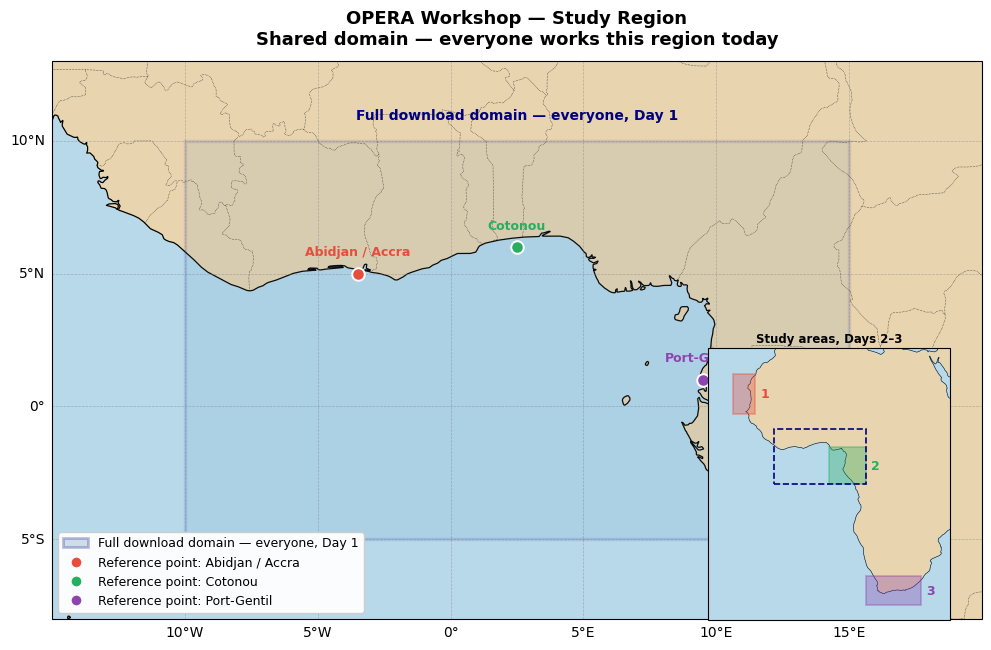

==> Map saved: Day1_study_region_map.png

   Main map : Full download domain — everyone, Day 1
   Inset    : 1 Mauritania/Senegal   2 Gulf of Guinea   3 Agulhas
              (dashed navy = the shared domain you are working today)


In [8]:
# ============================================================
# VISUALIZE THE STUDY REGION
# ─────────────────────────────────────────────────────────────
# Adapts to PHASE:
#   'shared' -> the full Gulf of Guinea download domain (Day 1)
#   'zone'   -> your own study area (Days 2-3)
# The inset shows where all three study areas sit on the
# continent, so you can see where yours is relative to today's.
# ============================================================

fig = plt.figure(figsize=(12, 8))
ax  = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([LON_MIN - 5, LON_MAX + 5, LAT_MIN - 3, LAT_MAX + 3],
              crs=ccrs.PlateCarree())

ax.add_feature(cfeature.LAND,      color='#E8D5B0', zorder=1)
ax.add_feature(cfeature.OCEAN,     color='#B8D9EA', zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, zorder=2)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', zorder=2)

# ---- the box we are actually working in ----
box_label = ('Full download domain — everyone, Day 1' if PHASE == 'shared'
             else f'Area {ACTIVE_ZONE} — {ZONE_NAME}')
ax.add_patch(mpatches.Rectangle(
    (LON_MIN, LAT_MIN), LON_MAX - LON_MIN, LAT_MAX - LAT_MIN,
    linewidth=2.5, edgecolor='navy', facecolor='steelblue', alpha=0.10,
    transform=ccrs.PlateCarree(), zorder=3))
ax.text((LON_MIN + LON_MAX) / 2, LAT_MAX + 0.8, box_label,
        ha='center', fontsize=10, color='navy', fontweight='bold',
        transform=ccrs.PlateCarree())

# ---- coastal reference points (these are PLACES, not areas) ----
colors  = ['#E74C3C', '#27AE60', '#8E44AD']
handles = [mpatches.Patch(edgecolor='navy', facecolor='steelblue',
                          alpha=0.25, lw=2, label=box_label)]

for (rlon, rlat, rname), color in zip(REF_POINTS, colors):
    label = rname.split('(')[0].strip()
    ax.plot(rlon, rlat, marker='o', markersize=9, color=color,
            markeredgecolor='white', markeredgewidth=1.4,
            transform=ccrs.PlateCarree(), zorder=6)
    ax.text(rlon, rlat + (LAT_MAX - LAT_MIN) * 0.045, label,
            ha='center', fontsize=9, fontweight='bold', color=color,
            transform=ccrs.PlateCarree(), zorder=6)
    handles.append(mlines.Line2D([], [], color=color, marker='o', linestyle='None',
                                 markersize=8, markeredgecolor='white',
                                 label=f'Reference point: {label}'))

gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray',
                  alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False
gl.xlocator = mticker.FixedLocator(np.arange(np.floor(LON_MIN/5)*5, LON_MAX + 6, 5))
gl.ylocator = mticker.FixedLocator(np.arange(np.floor(LAT_MIN/5)*5, LAT_MAX + 6, 5))

subtitle = ('Shared domain — everyone works this region today'
            if PHASE == 'shared'
            else Z['regime'])
ax.set_title(f'OPERA Workshop — Study Region\n{subtitle}',
             fontsize=13, fontweight='bold', pad=12)
ax.legend(handles=handles, loc='lower left', fontsize=9, framealpha=0.95)

# ---- inset: where the three study areas are on the continent ----
inset = fig.add_axes([0.655, 0.145, 0.235, 0.34], projection=ccrs.PlateCarree())
inset.set_extent([-28, 38, -42, 32], crs=ccrs.PlateCarree())
inset.add_feature(cfeature.LAND,      color='#E8D5B0')
inset.add_feature(cfeature.OCEAN,     color='#B8D9EA')
inset.add_feature(cfeature.COASTLINE, linewidth=0.4)

area_cols = {'1': '#E74C3C', '2': '#27AE60', '3': '#8E44AD'}
for k, z in ZONES.items():
    lo0, lo1 = z['lon']; la0, la1 = z['lat']
    inset.add_patch(mpatches.Rectangle(
        (lo0, la0), lo1 - lo0, la1 - la0,
        linewidth=1.4, edgecolor=area_cols[k],
        facecolor=area_cols[k], alpha=0.35,
        transform=ccrs.PlateCarree(), zorder=4))
    inset.text(lo1 + 1.5, (la0 + la1) / 2, k, fontsize=9, fontweight='bold',
               color=area_cols[k], va='center', transform=ccrs.PlateCarree())

# today's shared domain, dashed, for reference
inset.add_patch(mpatches.Rectangle(
    (SHARED['lon'][0], SHARED['lat'][0]),
    SHARED['lon'][1] - SHARED['lon'][0],
    SHARED['lat'][1] - SHARED['lat'][0],
    linewidth=1.2, edgecolor='navy', facecolor='none', linestyle='--',
    transform=ccrs.PlateCarree(), zorder=5))

inset.set_title('Study areas, Days 2–3', fontsize=8.5, fontweight='bold', pad=4)

plt.savefig(OUTPUT_DIR + '/Day1_study_region_map.png', dpi=150, bbox_inches='tight')
plt.show()

print('==> Map saved: Day1_study_region_map.png')
print()
print(f'   Main map : {box_label}')
print( '   Inset    : 1 Mauritania/Senegal   2 Gulf of Guinea   3 Agulhas')
print( '              (dashed navy = the shared domain you are working today)')


In [8]:
OUTPUT_DIR+'/Day1_study_region_map.png'

'/content/drive/MyDrive/OPERA_Workshop_Data/output/Day1/Day1_study_region_map.png'

---

##  Section 3 — CMEMS Account & Authentication

*Access Block  |  12:10–12:30  (20 min — before lunch)*



>  **Facilitation note:** 20 minutes, just before lunch. All Subgroup Instructors observe
> this plenary to align their breakout delivery. Participants watch with the script open —
> they run it themselves in the download block at 13:30.

---

### Registering for CMEMS (free)

1. Go to **https://marine.copernicus.eu/**
2. Click *Register* → complete the form → confirm your email
3. Return here and run the cell below

### How the login cell works

The cell **checks first** whether valid credentials already exist, and only prompts if they do not.
That matters here: several of you will already be logged in from an earlier session, and there is
no reason to make you type your password again.

`login(check_credentials_valid=True)` returns `True` or `False` without prompting. It looks for
credentials passed directly, then environment variables, then the stored file — and stops at the
first it finds. Once you do log in, they are cached at `~/.copernicusmarine/`, so it is once per machine.

>  **Security rule:** Never hardcode your password in a notebook cell.  
> Always use `copernicusmarine.login()` which prompts interactively.

---

| Role | Action |
|------|--------|
|  **Lead Instructor** | Run this cell during the plenary demo — show the login prompt on screen |
|  **Participant** | **Do NOT run today.** Study the code. Use it on your own machine after the workshop. |

---

In [9]:
# ============================================================
# CMEMS LOGIN  —  check first, only prompt if needed
# ─────────────────────────────────────────────────────────────
#  LEAD INSTRUCTOR -> run during the plenary demo (12:10–12:30)
#  PARTICIPANT     -> study today; run it on your own machine later
#
# WHY CHECK FIRST
# Calling login() straight away prompts every time, even when
# valid credentials are already cached. In a live session that
# wastes minutes and confuses people who logged in yesterday.
#
# login(check_credentials_valid=True) returns True/False WITHOUT
# prompting. It looks in this order and stops at the first hit:
#     1. username / password passed directly
#     2. COPERNICUSMARINE_SERVICE_USERNAME / _PASSWORD env vars
#     3. the stored credentials file
#
#  Never paste your password into a notebook cell.
# ============================================================

CRED_FILE = os.path.expanduser('~/.copernicusmarine/.copernicusmarine-credentials')

def cmems_ready():
    """True if usable CMEMS credentials already exist. Never prompts."""
    try:
        return bool(copernicusmarine.login(check_credentials_valid=True))
    except TypeError:
        # very old toolbox without the flag — fall back to the file
        return os.path.exists(CRED_FILE)
    except Exception as e:
        print(f'   could not check credentials: {type(e).__name__}: {e}')
        return False

print('Checking for existing CMEMS credentials...')
print()

if cmems_ready():
    print('   ==> Already logged in. Credentials valid — nothing to do.')
    print(f'       Stored at: {CRED_FILE}')
    print('       Downloads in Section 4 will work.')
else:
    print('   No valid credentials found.')
    print('   A prompt will now appear — enter your Copernicus Marine')
    print('   username and password. They are cached, so this is once')
    print('   per machine.')
    print()
    copernicusmarine.login()

    # confirm it actually worked rather than assuming
    print()
    if cmems_ready():
        print('   ==> Login successful, credentials verified.')
    else:
        print('   ==> Login did NOT verify. Common causes:')
        print('       - typo in username or password')
        print('       - email address not yet confirmed after registering')
        print('       - network blocking auth.marine.copernicus.eu')
        print('       Register or reset at https://marine.copernicus.eu/')


INFO - 2026-08-18T03:21:38Z - Checking if credentials are valid.
INFO:copernicusmarine:Checking if credentials are valid.
INFO - 2026-08-18T03:21:38Z - No credentials found.
INFO:copernicusmarine:No credentials found.
INFO - 2026-08-18T03:21:38Z - Please provide credentials as arguments or environment variables, or use the 'login' command to create a credentials file.
INFO:copernicusmarine:Please provide credentials as arguments or environment variables, or use the 'login' command to create a credentials file.
INFO - 2026-08-18T03:21:38Z - Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register
INFO:copernicusmarine:Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register


Checking for existing CMEMS credentials...

   No valid credentials found.
   A prompt will now appear — enter your Copernicus Marine
   username and password. They are cached, so this is once
   per machine.

Copernicus Marine username: btchonant
Copernicus Marine password: ··········


INFO - 2026-08-18T03:21:50Z - Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.
INFO:copernicusmarine:Credentials file stored in /root/.copernicusmarine/.copernicusmarine-credentials.
INFO - 2026-08-18T03:21:50Z - Checking if credentials are valid.
INFO:copernicusmarine:Checking if credentials are valid.


INFO - 2026-08-18T03:21:51Z - Valid credentials from configuration file.
INFO:copernicusmarine:Valid credentials from configuration file.


   ==> Login successful, credentials verified.


---

##  Section 4 — Data Download: Four Datasets, Two Services

*Download Block  |  13:30–15:00  (90 min — instructor demonstrates)*


### The four datasets

| # | Dataset | Source | Resolution | Why we need it |
|---|---------|--------|-----------|----------------|
| 1 | **Sea Surface Temperature** reanalysis | CMEMS | daily, 0.05° | Upwelling, warm pools, marine heatwaves — the ocean's most visible signal |
| 2 | **Sea Surface Height** altimetry (SLA + ADT) | CMEMS | daily, 0.125° | Geostrophic currents, eddies, sea level trends |
| 3 | **Surface currents** (total, Ekman, geostrophic) | CMEMS | daily, 0.25° | Transport, and the Ekman component the wind drives directly |
| 4 | **Wind and wind stress** | **CDS / ERA5** | monthly, 0.25° | The *forcing*. Everything above is the ocean's response to it |

### Why is the wind not from CMEMS?

**It could be.** CMEMS does publish wind — `WIND_GLO_PHY_CLIMATE_L4_MY_012_003`, global monthly wind and stress at 0.25°. It is a good product and it stays in this notebook as a one-line fallback (`WIND_SOURCE = 'CMEMS'`).

We use **ERA5** instead on purpose, for three reasons:

1. **Ocean forecasting is not fed by one service.** Fernand's Chapter 3 listed where model forcing comes from — *observations, atmospheric reanalyses, forecast products*. ERA5 is that atmospheric reanalysis. Learning to reach for the right service is part of the job.
2. **A second ecosystem means a second set of habits** — a different client (`cdsapi`), different credentials, a different way of writing a bounding box, and a queue instead of a direct download. Meeting that once, with support, beats meeting it alone later.
3. **Module 5 of the MOOC is upstream data sources.** This is that module, made concrete.

> If the CDS queue is slow on the day, switch `WIND_SOURCE` to `'CMEMS'` and move on. The science does not change — only which door you walk through.

All four are **global** products, so the same request works for any region — only the bounding box changes. Note that the first three use CMEMS dataset IDs and the fourth uses an ERA5 dataset name; the idea is the same, the syntax differs.

### Who runs these cells

> **Instructor** runs the download cells. **Participants study them and can run if they want**.
>
> Read them properly, though — the anatomy of a `subset()` call (dataset ID, variables, bounding box, time range, output path) is what you will reuse for in your own research.

If you want the full daily record for your own zone, **section 4.5** gives you a resumable download you can continue in your own time.

---

### Who downloads what, and when

There are **four regions** in play — the shared domain everyone uses today, plus the three smaller study areas for Days 2 and 3. They are not all downloaded the same way.

| Region | Files | Who downloads it | When |
|--------|-------|------------------|------|
| **Shared domain** (Gulf of Guinea, 10°W–15°E) | `GOG_*.nc` | **Instructor**, in advance | Before the workshop |
| **Area 1** — Mauritania / Senegal | `MRS_*.nc` | Instructor in advance **and/or** you, in section 4.5 | Before / this evening |
| **Area 2** — Gulf of Guinea east | `GOG_*.nc` | Nobody — it is a **slice** of the shared files | Already covered |
| **Area 3** — Agulhas | `AGU_*.nc` | Instructor in advance **and/or** you, in section 4.5 | Before / this evening |

**Area 2 needs no separate download.** It sits inside the shared domain, so the group working it simply narrows the bounding box. Areas 1 and 3 are elsewhere on the continent, so they are genuine separate downloads.

> **Instructor:** to fetch every region in one pass, set `ALL_DOMAINS = True` in the download helper below and run cells 4.1–4.4. That loops over the shared domain plus Areas 1 and 3. Do this **days ahead** — it is several gigabytes and CMEMS throughput varies.
>
> **Participants:** leave `ALL_DOMAINS = False`. Today you only need the shared domain, which is already staged for you. If you want the full daily record for **your own area**, that is section 4.5 — set `ACTIVE_ZONE` to your group number first.

---


In [10]:
# ============================================================
# 4.0a — DIRECTORY & FILE PATHS  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# FOUR datasets per domain — SST, SSH, currents and WIND.
# File names carry the domain prefix so everything coexists:
#     GOG_*.nc   shared domain and Area 2
#     MRS_*.nc   Area 1, Mauritania / Senegal
#     AGU_*.nc   Area 3, Agulhas
#
# Running locally after the workshop? Uncomment:
# DATA_DIR = './data'
# ============================================================

os.makedirs(DATA_DIR, exist_ok=True)

def zone_files(prefix):
    """Return the four file paths for a given domain prefix."""
    return dict(
        SST  = os.path.join(DATA_DIR, f'{prefix}_SST_reanalysis.nc'),
        SSH  = os.path.join(DATA_DIR, f'{prefix}_SSH_altimetry.nc'),
        CURR = os.path.join(DATA_DIR, f'{prefix}_currents.nc'),
        WIND = os.path.join(DATA_DIR, f'{prefix}_wind_monthly.nc'),
    )

FILES     = zone_files(FILE_PREFIX)
SST_FILE  = FILES['SST']
SSH_FILE  = FILES['SSH']
CURR_FILE = FILES['CURR']
WIND_FILE = FILES['WIND']

print(f'==> Files for {DOMAIN_NAME}  (prefix {FILE_PREFIX})')
print(f'   DATA_DIR : {DATA_DIR}')
print()
for label, fpath in FILES.items():
    exists = os.path.exists(fpath)
    size   = f'  ({os.path.getsize(fpath)/1e6:.0f} MB)' if exists else ''
    status = f'exists{size}' if exists else 'NOT YET DOWNLOADED'
    print(f'   {label:<5} -> {os.path.basename(fpath):<30} [{status}]')
print()
print('   Missing files? Ask your Subgroup Instructor, or run 4.0b')
print('   for a full check of every domain.')

==> Files for Gulf of Guinea (shared domain)  (prefix GOG)
   DATA_DIR : /content/drive/MyDrive/OPERA_Workshop_Data/data

   SST   -> GOG_SST_reanalysis.nc          [exists  (1534 MB)]
   SSH   -> GOG_SSH_altimetry.nc           [exists  (982 MB)]
   CURR  -> GOG_currents.nc                [exists  (614 MB)]
   WIND  -> GOG_wind_monthly.nc            [exists  (4 MB)]

   Missing files? Ask your Subgroup Instructor, or run 4.0b
   for a full check of every domain.


---

### 4.0b — What is already on your Drive?

**Run this before any download.** It opens every file it finds and reports whether it is genuinely usable, so you know what will actually happen when you run 4.1–4.4.

Nothing is downloaded twice. A file that is present and complete is skipped; one that is present but truncated or for the wrong region is deleted and fetched again.
---


In [11]:
# ============================================================
# 4.0b — INVENTORY: WHAT IS ALREADY ON THE DRIVE
# ─────────────────────────────────────────────────────────────
# Read-only. Downloads nothing. FULLY SELF-CONTAINED — it needs
# only DATA_DIR and the zone configuration, so it runs even if
# the file-path cell (4.0) and the download helper (4.1) have
# not been executed yet.
#
# Run it BEFORE 4.1-4.4 so there are no surprises, and again
# afterwards to confirm.
# ============================================================

import os
import xarray as _xr
import numpy as _np

EXPECT_VAR = {'SST': ['analysed_sst'], 'SSH': ['sla'], 'CURR': ['uo'],
              'WIND': ['u10', 'eastward_wind']}


def zone_files(prefix):
    """The four file paths for a given domain prefix."""
    return dict(
        SST  = os.path.join(DATA_DIR, f'{prefix}_SST_reanalysis.nc'),
        SSH  = os.path.join(DATA_DIR, f'{prefix}_SSH_altimetry.nc'),
        CURR = os.path.join(DATA_DIR, f'{prefix}_currents.nc'),
        WIND = os.path.join(DATA_DIR, f'{prefix}_wind_monthly.nc'),
    )


def domains():
    """Domains to inspect: the shared box plus any zone with its own files."""
    out = {SHARED['prefix']: SHARED}
    for z in ZONES.values():
        if z['prefix'] != SHARED['prefix']:
            out[z['prefix']] = z
    return out


def data_status(kind, dom):
    """Return ('ok'|'partial'|'missing', message) for one product/domain.

    'ok'      -> present AND opens AND covers the period and box
    'partial' -> present but truncated, wrong region, or unreadable
    'missing' -> nothing there
    """
    out = zone_files(dom['prefix'])[kind]
    if not os.path.exists(out):
        return 'missing', 'not downloaded'

    mb = os.path.getsize(out) / 1e6
    try:
        with _xr.open_dataset(out, engine='h5netcdf') as ds:
            if not any(v in ds.variables for v in EXPECT_VAR[kind]):
                return 'partial', f'{mb:.0f} MB but no {EXPECT_VAR[kind][0]}'

            # CMEMS calls it 'time'; ERA5 from the new CDS calls it 'valid_time'
            tname = ('time' if 'time' in ds.sizes
                     else 'valid_time' if 'valid_time' in ds.sizes else None)
            if tname is None:
                return 'partial', f'{mb:.0f} MB but no time axis'

            tol   = _np.timedelta64(35, 'D')
            got0  = _np.datetime64(str(ds[tname].values[0])[:10])
            got1  = _np.datetime64(str(ds[tname].values[-1])[:10])
            want0 = _np.datetime64(DATE_START[:10])
            want1 = _np.datetime64(DATE_END[:10])
            if got0 - want0 > tol or want1 - got1 > tol:
                return 'partial', (f'{mb:.0f} MB, covers {str(got0)[:10]} to '
                                   f'{str(got1)[:10]} — incomplete')

            latn = 'latitude'  if 'latitude'  in ds.coords else 'lat'
            lonn = 'longitude' if 'longitude' in ds.coords else 'lon'
            if latn in ds.coords and lonn in ds.coords:
                if (float(ds[latn].min()) > dom['lat'][0] + 1 or
                    float(ds[latn].max()) < dom['lat'][1] - 1 or
                    float(ds[lonn].min()) > dom['lon'][0] + 1 or
                    float(ds[lonn].max()) < dom['lon'][1] - 1):
                    return 'partial', f'{mb:.0f} MB but wrong region'

            return 'ok', f'{mb:.0f} MB, {ds.sizes[tname]} steps'
    except Exception as e:
        return 'partial', f'{mb:.0f} MB but will not open ({type(e).__name__})'


# ---------------------------- report ----------------------------
print('=' * 70)
print(f'   DRIVE INVENTORY   —   {DATA_DIR}')
print('=' * 70)

MARK = {'ok': '[ok     ]', 'partial': '[partial]', 'missing': '[missing]'}
need_download, need_redo, already = [], [], []

for dom in domains().values():
    print(f'\n  {dom["prefix"]}  —  {dom["name"]}')
    for kind in ['SST', 'SSH', 'CURR', 'WIND']:
        status, detail = data_status(kind, dom)
        print(f'     {MARK[status]} {kind:<5} {detail}')
        {'ok': already, 'partial': need_redo,
         'missing': need_download}[status].append(f'{dom["prefix"]}/{kind}')

print()
print('  ' + '-' * 66)
print(f'  Ready to use     : {len(already)}')
print(f'  Will re-download : {len(need_redo)}   {", ".join(need_redo)}')
print(f'  Will download    : {len(need_download)}   {", ".join(need_download)}')
print()

if not need_download and not need_redo:
    print('  ==> Everything is already here. Cells 4.1-4.4 will skip all')
    print('      downloads. Go straight to the readiness check (4.6).')
elif not need_download:
    print('  ==> Some files are incomplete. Running 4.1-4.4 will replace')
    print('      only those — the good ones are left alone.')
else:
    print('  ==> Run cells 4.1-4.4. Only the missing items are fetched.')
print('=' * 70)

   DRIVE INVENTORY   —   /content/drive/MyDrive/OPERA_Workshop_Data/data

  GOG  —  Gulf of Guinea (shared domain)
     [ok     ] SST   1534 MB, 5113 steps
     [ok     ] SSH   982 MB, 5113 steps
     [ok     ] CURR  614 MB, 5113 steps
     [ok     ] WIND  4 MB, 168 steps

  MRS  —  Mauritania / Senegal
     [ok     ] SST   270 MB, 5113 steps
     [ok     ] SSH   173 MB, 5113 steps
     [ok     ] CURR  108 MB, 5113 steps
     [ok     ] WIND  1 MB, 168 steps

  AGU  —  Agulhas
     [ok     ] SST   491 MB, 5113 steps
     [ok     ] SSH   314 MB, 5113 steps
     [ok     ] CURR  196 MB, 5113 steps
     [ok     ] WIND  2 MB, 168 steps

  ------------------------------------------------------------------
  Ready to use     : 12
  Will re-download : 0   
  Will download    : 0   

  ==> Everything is already here. Cells 4.1-4.4 will skip all
      downloads. Go straight to the readiness check (4.6).


---

### 4.1 — Download 1: Sea Surface Temperature (SST) Reanalysis

*within Download Block  |  13:30–13:50*


**CMEMS product:** METOFFICE-GLO-SST-L4-REP-OBS-SST  
**Variable:** `analysed_sst` — daily sea surface temperature in **Kelvin** (converted to °C in Section 5)  
**Product type:** L4 Reanalysis — satellite observations gap-filled and quality-controlled, complete daily global field

> **MOOC connection:** Module 5 introduced CMEMS product families. This is an L4 *reanalysis* product:  
> it uses all available satellite observations and fills spatial gaps via optimal interpolation,  
> giving a seamless daily SST field from 1993 to the near-present.

> **Expected download:** ~1534–1600 MB | ~5–15 minutes

>  **Instructor:** Run the cell below.   **Participant:** Study every line and comment.

In [12]:
# ============================================================
# DOWNLOAD HELPER  —  serves all four datasets, all domains
# ─────────────────────────────────────────────────────────────
#  INSTRUCTOR  -> run BEFORE the workshop with ALL_DOMAINS=True
#  PARTICIPANT -> study these cells. Do NOT run them today.
#
# All four products are GLOBAL, so the same dataset IDs serve
# every zone — only the bounding box changes.
#
# TOOLBOX VERSION NOTE
# force_download was removed in copernicusmarine v2, so it is
# not used here. The os.path.exists() guard does the same job.
# ============================================================

ALL_DOMAINS = True        # True = fetch shared domain + all three zones

# ---- wind dataset ID -------------------------------------------------
# Product: WIND_GLO_PHY_CLIMATE_L4_MY_012_003
#   Global monthly L4 wind and stress, 0.25 deg, ERA5 corrected
#   with ASCAT / QuikSCAT / ERS scatterometer observations.
# Monthly is the right choice here: hourly would be ~700x larger
# for no pedagogical gain.
#
# Dataset IDs carry version suffixes that change. RESOLVE IT
# rather than trusting a hardcoded string:
WIND_PRODUCT_ID = 'WIND_GLO_PHY_CLIMATE_L4_MY_012_003'
WIND_DATASET_ID = None     # filled by resolve_wind_id() below

def resolve_wind_id(product_id=WIND_PRODUCT_ID):
    """Look up the current dataset ID for the monthly wind product."""
    global WIND_DATASET_ID
    try:
        cat = copernicusmarine.describe(contains=[product_id])
        ids = []
        for p in cat.get('products', []):
            for ds in p.get('datasets', []):
                ids.append(ds.get('dataset_id'))
        ids = [i for i in ids if i]
        if ids:
            print('   Available wind dataset IDs:')
            for i in ids:
                print(f'     - {i}')
            WIND_DATASET_ID = ids[0]
            print(f'   Using: {WIND_DATASET_ID}')
        else:
            print('   !! No dataset IDs returned — set WIND_DATASET_ID by hand')
    except Exception as e:
        print(f'   !! describe() failed: {e}')
        print('      Set WIND_DATASET_ID manually from the product page.')
    return WIND_DATASET_ID

DATASETS = {
    'SST':  dict(dataset_id = 'METOFFICE-GLO-SST-L4-REP-OBS-SST',
                 variables   = ['analysed_sst'],
                 label       = 'SST reanalysis (daily, 0.05 deg)'),
    'SSH':  dict(dataset_id = 'cmems_obs-sl_glo_phy-ssh_my_allsat-l4-duacs-0.125deg_P1D',
                 variables   = ['sla', 'adt'],
                 label       = 'SSH altimetry (daily, 0.125 deg)'),
    'CURR': dict(dataset_id = 'cmems_obs-mob_glo_phy-cur_my_0.25deg_P1D-m',
                 variables   = ['uo', 'vo', 'ue', 've', 'ugos', 'vgos'],
                 label       = 'Surface currents (daily, 0.25 deg)'),
    'WIND': dict(dataset_id = None,   # resolved at runtime
                 variables   = ['eastward_wind', 'northward_wind',
                                'surface_downward_eastward_stress',
                                'surface_downward_northward_stress'],
                 label       = 'Wind and stress (monthly, 0.25 deg)'),
}

def domains():
    """Domains to fetch: the shared box plus each zone that needs its own."""
    out = {SHARED['prefix']: SHARED}
    for zk, z in ZONES.items():
        if z['prefix'] != SHARED['prefix']:
            out[z['prefix']] = z
    if not ALL_DOMAINS:
        cur = SHARED if PHASE == 'shared' else ZONES[ACTIVE_ZONE]
        return {cur['prefix']: cur}
    return out


# ---- is the data already on the Drive, and is it usable? -------------
EXPECT_VAR = {'SST': ['analysed_sst'], 'SSH': ['sla'], 'CURR': ['uo'],
              'WIND': ['u10', 'eastward_wind']}

def data_status(kind, dom):
    """Return ('ok'|'partial'|'missing', message) for one product/domain.

    'ok'      -> file present AND opens AND covers the period and box
    'partial' -> file present but truncated, wrong region, or unreadable
    'missing' -> nothing there

    Existence alone is not enough: an interrupted download leaves a file
    that os.path.exists() happily accepts and that fails days later.
    """
    out = zone_files(dom['prefix'])[kind]
    if not os.path.exists(out):
        return 'missing', 'not downloaded'

    mb = os.path.getsize(out) / 1e6
    try:
        import xarray as _xr
        with _xr.open_dataset(out, engine='h5netcdf') as ds:
            if not any(v in ds.variables for v in EXPECT_VAR[kind]):
                return 'partial', f'{mb:.0f} MB but no {EXPECT_VAR[kind][0]}'

            if 'time' not in ds.sizes:
                return 'partial', f'{mb:.0f} MB but no time axis'

            import numpy as _np
            tol   = _np.timedelta64(35, 'D')
            got0  = _np.datetime64(str(ds.time.values[0])[:10])
            got1  = _np.datetime64(str(ds.time.values[-1])[:10])
            want0 = _np.datetime64(DATE_START[:10])
            want1 = _np.datetime64(DATE_END[:10])
            if got0 - want0 > tol or want1 - got1 > tol:
                return 'partial', (f'{mb:.0f} MB, covers {str(got0)[:10]} to '
                                   f'{str(got1)[:10]} — incomplete')

            latn = 'latitude'  if 'latitude'  in ds.coords else 'lat'
            lonn = 'longitude' if 'longitude' in ds.coords else 'lon'
            if latn in ds.coords and lonn in ds.coords:
                if (float(ds[latn].min()) > dom['lat'][0] + 1 or
                    float(ds[latn].max()) < dom['lat'][1] - 1 or
                    float(ds[lonn].min()) > dom['lon'][0] + 1 or
                    float(ds[lonn].max()) < dom['lon'][1] - 1):
                    return 'partial', f'{mb:.0f} MB but wrong region'

            return 'ok', f'{mb:.0f} MB, {ds.sizes["time"]} steps'
    except Exception as e:
        return 'partial', f'{mb:.0f} MB but will not open ({type(e).__name__})'

def fetch(kind, dom):
    """Download one dataset for one domain, skipping if present."""
    spec = DATASETS[kind]
    out  = zone_files(dom['prefix'])[kind]

    status, detail = data_status(kind, dom)
    if status == 'ok':
        print(f'   [skip] {dom["prefix"]} {kind:<4} already on Drive — {detail}')
        return
    if status == 'partial':
        print(f'   [redo] {dom["prefix"]} {kind:<4} unusable — {detail}')
        print(f'          deleting and downloading again')
        os.remove(out)

    ds_id = spec['dataset_id'] or (WIND_DATASET_ID if kind == 'WIND' else None)
    if ds_id is None:
        print(f'   [stop] {kind}: dataset ID unresolved — run resolve_wind_id()')
        return

    print(f'   [get ] {dom["prefix"]} — {spec["label"]}')
    print(f'          lon [{dom["lon"][0]}, {dom["lon"][1]}]  '
          f'lat [{dom["lat"][0]}, {dom["lat"][1]}]')

    copernicusmarine.subset(
        dataset_id        = ds_id,
        variables         = spec['variables'],
        minimum_longitude = dom['lon'][0],
        maximum_longitude = dom['lon'][1],
        minimum_latitude  = dom['lat'][0],
        maximum_latitude  = dom['lat'][1],
        start_datetime    = f'{DATE_START}T00:00:00',
        end_datetime      = f'{DATE_END}T23:59:59',
        output_filename   = out,
    )
    print(f'          done — {os.path.getsize(out)/1e6:.0f} MB')

print('==> Download helper ready')
print(f'   ALL_DOMAINS = {ALL_DOMAINS}')
print(f'   Will fetch : {", ".join(domains().keys())}')


==> Download helper ready
   ALL_DOMAINS = True
   Will fetch : GOG, MRS, AGU


In [13]:
# ============================================================
# DOWNLOAD: SST REANALYSIS
#  INSTRUCTOR -> run.   PARTICIPANT -> study, do not run.
# ============================================================

print('SST REANALYSIS')
for dom in domains().values():
    fetch('SST', dom)
print('\\n==> SST step complete')


SST REANALYSIS
   [skip] GOG SST  already on Drive — 1534 MB, 5113 steps
   [skip] MRS SST  already on Drive — 270 MB, 5113 steps
   [skip] AGU SST  already on Drive — 491 MB, 5113 steps
\n==> SST step complete


---

### 4.2 — Download 2: Sea Surface Height (SSH) Altimetry

*within Download Block  |  13:50–14:05*


**CMEMS product:** DUACS multimission altimetry — 0.125° daily  
**Variables:** `sla` (Sea Level Anomaly) and `adt` (Absolute Dynamic Topography)

| Variable | Physical meaning |
|----------|-----------------|
| `sla` | Deviation of sea level from the long-term mean — reveals eddies, upwelling, sea level trends |
| `adt` | Absolute sea surface height above geoid — used to derive geostrophic surface currents |

> **MOOC connection:** Module 4 covered radar altimetry as an observing system.  
> Module 6 covered how to read SSH maps: positive SLA = anti-cyclonic warm eddy; negative SLA = cyclonic cold eddy or upwelling.

> **Expected download:** ~900–1000 MB | ~5–15 minutes

>  **Instructor:** Run below.   **Participant:** Study — note TWO variables extracted in one call.

In [14]:
# ============================================================
# DOWNLOAD: SSH ALTIMETRY
#  INSTRUCTOR -> run.   PARTICIPANT -> study, do not run.
# ============================================================

print('SSH ALTIMETRY')
for dom in domains().values():
    fetch('SSH', dom)
print('\\n==> SSH step complete')


SSH ALTIMETRY
   [skip] GOG SSH  already on Drive — 982 MB, 5113 steps
   [skip] MRS SSH  already on Drive — 173 MB, 5113 steps
   [skip] AGU SSH  already on Drive — 314 MB, 5113 steps
\n==> SSH step complete


---

### 4.3 — Download 3: Surface Currents

*within Download Block  |  14:05–14:20*


**CMEMS product:** Global surface currents — multi-observation reprocessed, 0.25° daily  
**Variables:** Six components across three physical decompositions

| Variable pair | Component | Physical driver |
|--------------|-----------|----------------|
| `uo` / `vo` | Total surface current | Combined |
| `ue` / `ve` | Ekman component | Wind-driven (Ekman transport) |
| `ugos` / `vgos` | Geostrophic component | Pressure-gradient driven |

> **MOOC connection:** Module 2 covered geostrophic balance and Ekman circulation.  
> Downloading all three components lets us separate what fraction of Gulf of Guinea surface flow  
> is wind-forced (Ekman upwelling) vs. pressure-driven (geostrophic eddies) — key for Module 7 applications.

> **Expected download:** ~600–700 MB | ~10–20 minutes (largest file)

>  **Instructor:** Run below.   **Participant:** Study — note SIX variables in one call.

In [15]:
# ============================================================
# DOWNLOAD: SURFACE CURRENTS
#  INSTRUCTOR -> run.   PARTICIPANT -> study, do not run.
# ============================================================

print('SURFACE CURRENTS')
for dom in domains().values():
    fetch('CURR', dom)
print('\\n==> CURR step complete')


SURFACE CURRENTS
   [skip] GOG CURR already on Drive — 614 MB, 5113 steps
   [skip] MRS CURR already on Drive — 108 MB, 5113 steps
   [skip] AGU CURR already on Drive — 196 MB, 5113 steps
\n==> CURR step complete


---

### 4.4 — Download 4: Atmospheric Forcing from ERA5

*within Download Block  |  14:20–14:45  (different service — allow extra time)*


Wind is where Module 2 comes back. Gaël's Chapter 4 opened with one claim — **wind is the main dynamic forcing over the ocean** — and the Ekman spiral, coastal upwelling, Ekman pumping and the subtropical gyres all descend from it. Until now this notebook has shown you the ocean's *response*. Now we get the *forcing*.

**But notice where we are getting it from.** Everything so far came from CMEMS. Wind does not.

Fernand's Chapter 3 listed where model forcing comes from: *observations, atmospheric reanalyses, or forecast products*. **ERA5 is that atmospheric reanalysis** — produced by ECMWF, distributed through the **Copernicus Climate Data Store (CDS)**, and used to force ocean models worldwide, including many CMEMS products.

So this cell teaches something the other three could not: **ocean forecasting draws on more than one data ecosystem, and you need to be fluent in both.**

| | CMEMS | CDS / ERA5 |
|---|---|---|
| What it holds | Ocean | Atmosphere, climate |
| Python client | `copernicusmarine` | `cdsapi` |
| Credentials | `login()`, stored token | `~/.cdsapirc` personal access token |
| Region syntax | `minimum_longitude`, `maximum_latitude` … | `area = [North, West, South, East]` |
| Delivery | Direct download | **Queued** — seconds to hours |

### Before you can run this

1. Register at **cds.climate.copernicus.eu** (separate from your CMEMS account)
2. Open your profile and copy the **personal access token**
3. **Accept the licence** on the ERA5 monthly-means dataset page — this is the single most common failure; the API returns a permissions error until you do
4. Write the credentials to `~/.cdsapirc`

> **CDS requests are queued.** A small request usually returns in a few minutes, but at busy times it can be much longer. **This is why your instructor has staged the file** — never make a live session depend on a queue.

### Two traps worth seeing

- **The bounding box is `[North, West, South, East]`** — a different order and a different idea from the CMEMS min/max pairs. Getting it wrong returns a valid file for the wrong part of the planet.
- **ERA5 latitudes run north to south** (descending), while CMEMS run south to north. Plot one on the other without checking and your map is upside down. The code below sorts it.

---


In [16]:
# ============================================================
# CDS CREDENTIALS  (Colab Secrets — token never appears in the notebook)
# ─────────────────────────────────────────────────────────────
# 1. Register at https://cds.climate.copernicus.eu/
# 2. Profile -> copy your Personal Access Token
# 3. Colab left sidebar -> key icon -> add secret:
#       name  = CDSAPI_KEY
#       value = your token
#       toggle "Notebook access" ON
# 4. ACCEPT THE LICENCE on the ERA5 monthly-means dataset page,
#    or every request returns a permissions error.
# ============================================================

import os

CDS_URL = 'https://cds.climate.copernicus.eu/api'

try:
    from google.colab import userdata
    token = userdata.get('CDSAPI_KEY')
    source = 'Colab Secrets'
except Exception:
    token = os.environ.get('CDSAPI_KEY')
    source = 'environment variable'

if not token:
    print('==> No CDS token found.')
    print('    Add it via the key icon in the left sidebar as CDSAPI_KEY,')
    print('    then re-run this cell.')
    print('    Or skip ERA5 entirely: set WIND_SOURCE = "CMEMS" in 4.4.')
else:
    # cdsapi reads these two env vars, so no file is needed at all
    os.environ['CDSAPI_URL'] = CDS_URL
    os.environ['CDSAPI_KEY'] = token
    print(f'==> CDS credentials loaded from {source}.')
    print(f'    URL   : {CDS_URL}')
    print(f'    Token : {token[:4]}...{token[-4:]}  ({len(token)} chars)')
    print()
    try:
        import cdsapi
        cdsapi.Client()
        print('==> cdsapi client initialised. Ready for 4.4.')
    except ImportError:
        print('    cdsapi not installed — run:  !pip install cdsapi -q')
    except Exception as e:
        print(f'    Client failed: {type(e).__name__}: {e}')

==> CDS credentials loaded from Colab Secrets.
    URL   : https://cds.climate.copernicus.eu/api
    Token : 0ae0...00f5  (36 chars)

==> cdsapi client initialised. Ready for 4.4.


In [17]:
# ============================================================
# DOWNLOAD: ATMOSPHERIC FORCING — ERA5 MONTHLY WINDS
#  INSTRUCTOR -> run.   PARTICIPANT -> study, do not run today.
# ─────────────────────────────────────────────────────────────
# A DIFFERENT SERVICE from the three cells above:
#   ocean   -> CMEMS  via copernicusmarine
#   weather -> CDS    via cdsapi
#
# THREE CONVENTIONS DIFFER — all three bite in practice:
#   bounding box : CMEMS min/max pairs   vs  ERA5 [N, W, S, E]
#   latitude     : CMEMS ascending       vs  ERA5 descending
#   time axis    : CMEMS 'time'          vs  ERA5 'valid_time'
# The helpers below normalise all three.
#
# THIS CELL NEVER DELETES A FILE. If something looks wrong it
# says so and prints the exact command for you to run yourself.
# ============================================================

# !pip install cdsapi -q          # uncomment on first run in Colab

import os
import xarray as _xr

WIND_SOURCE = 'ERA5'      # 'ERA5' (taught) or 'CMEMS' (fallback)

ERA5_DATASET = 'reanalysis-era5-single-levels-monthly-means'
ERA5_VARS    = ['10m_u_component_of_wind', '10m_v_component_of_wind']


def normalise_wind(ds):
    """Make an ERA5 or CMEMS wind file look the same downstream.

    ERA5 from the new CDS uses 'valid_time' and carries singleton
    'number' / 'expver' coordinates. CMEMS uses 'time' and has neither.
    """
    if 'valid_time' in ds.dims and 'time' not in ds.dims:
        ds = ds.rename({'valid_time': 'time'})
    return ds.drop_vars(['number', 'expver'], errors='ignore')


def wind_components(ds):
    """Return (u, v) whichever naming the file uses, latitude ascending."""
    ds = normalise_wind(ds)

    if 'u10' in ds.variables:
        u, v = ds['u10'], ds['v10']
    elif 'eastward_wind' in ds.variables:
        u, v = ds['eastward_wind'], ds['northward_wind']
    else:
        raise KeyError(f'No recognised wind variables in {list(ds.data_vars)}')

    latname = 'latitude' if 'latitude' in ds.coords else 'lat'
    if ds[latname].size > 1 and ds[latname][0] > ds[latname][-1]:
        u = u.sortby(latname)
        v = v.sortby(latname)
    return u, v


def wind_on_drive(path):
    """Inspect a wind file. Returns (verdict, message). Never deletes.

    verdict: 'good' | 'odd' | 'unreadable' | 'absent'
    """
    if not os.path.exists(path):
        return 'absent', 'not downloaded'

    mb = os.path.getsize(path) / 1e6
    try:
        with _xr.open_dataset(path, engine='h5netcdf') as ds:
            tname = ('time' if 'time' in ds.sizes
                     else 'valid_time' if 'valid_time' in ds.sizes else None)
            wvars = [v for v in ('u10', 'eastward_wind') if v in ds.variables]
            if tname and wvars:
                return 'good', (f'{mb:.0f} MB, {ds.sizes[tname]} steps '
                                f'on "{tname}", {wvars[0]}')
            return 'odd', (f'{mb:.0f} MB, time axis={tname}, '
                           f'wind vars={wvars or "none"}')
    except Exception as e:
        return 'unreadable', f'{mb:.0f} MB, will not open ({type(e).__name__})'


def download_era5_wind(dom):
    """Fetch monthly 10 m winds for one domain. Assumes the file is absent."""
    import cdsapi
    out = zone_files(dom['prefix'])['WIND']
    lon0, lon1 = dom['lon']
    lat0, lat1 = dom['lat']

    print(f'   [get ] {dom["prefix"]} — ERA5 10 m winds, monthly')
    print(f'          area = [N {lat1}, W {lon0}, S {lat0}, E {lon1}]')
    print( '          queued at CDS — accepted -> running -> successful')

    cdsapi.Client().retrieve(
        ERA5_DATASET,
        {
            'product_type': ['monthly_averaged_reanalysis'],
            'variable'    : ERA5_VARS,
            'year'        : [str(y) for y in range(2010, 2024)],
            'month'       : [f'{m:02d}' for m in range(1, 13)],
            'time'        : ['00:00'],
            # ERA5 order is NORTH, WEST, SOUTH, EAST — not min/max pairs
            'area'           : [lat1, lon0, lat0, lon1],
            'data_format'    : 'netcdf',
            'download_format': 'unarchived',
        },
        out,
    )
    print(f'          done — {os.path.getsize(out)/1e6:.0f} MB')


# ------------------------------ run ------------------------------
print(f'WIND SOURCE: {WIND_SOURCE}')
print()

if WIND_SOURCE == 'ERA5':
    for dom in domains().values():
        path = zone_files(dom['prefix'])['WIND']
        verdict, msg = wind_on_drive(path)

        if verdict == 'good':
            print(f'   [skip] {dom["prefix"]} WIND — {msg}')
            continue

        if verdict in ('odd', 'unreadable'):
            print(f'   [warn] {dom["prefix"]} WIND — {msg}')
            print( '          NOT deleting. Look at it first:')
            print(f'             xr.open_dataset({path!r})')
            print( '          If you are sure it is bad, remove it yourself:')
            print(f'             os.remove({path!r})')
            continue

        try:
            download_era5_wind(dom)
        except ImportError:
            print('   cdsapi not installed — run:  !pip install cdsapi -q')
            break
        except Exception as e:
            print(f'   FAILED: {type(e).__name__}: {e}')
            print('   Common causes:')
            print('     - licence not accepted on the ERA5 dataset page')
            print('     - CDS token missing (see the credentials cell above)')
            print('     - request still queued; try again shortly')
            print('   -> fall back with WIND_SOURCE = "CMEMS"')
            break
else:
    print('Using the CMEMS wind product instead of ERA5.')
    resolve_wind_id()
    for dom in domains().values():
        fetch('WIND', dom)

print('\n==> Wind step complete')

WIND SOURCE: ERA5

   [skip] GOG WIND — 4 MB, 168 steps on "valid_time", u10
   [skip] MRS WIND — 1 MB, 168 steps on "valid_time", u10
   [skip] AGU WIND — 2 MB, 168 steps on "valid_time", u10

==> Wind step complete


---

## 4.5 — Downloading the Full Daily Record Yourself

*within Download Block  |  14:45–14:55  (briefing only — you run this tonight)*


The staged files give you everything you need for Days 2 and 3. This section is for pulling **the full 14-year daily record for your own zone** — which you may want to continue at home this evening.

**Set `ACTIVE_ZONE` to your group number before running this.** The cell below downloads *your study area* — not the shared domain — because that is what you will need on Days 2 and 3.

If you are in **Area 2**, you do not need this at all: your area is inside the shared domain, which you already have.

**The whole point of this section is that it can be interrupted.**

A single `subset()` call for 14 years is one long transaction: if your connection drops, Colab times out, or you close your laptop, you get *nothing* and start again. So we download **one year at a time**, into one file per year. If year 7 fails, years 1–6 are safe on disk and re-running resumes at year 7.

| | |
|---|---|
| One year, one domain, all three daily products | **60–350 MB** |
| Full 14 years, your zone | 0.9–4.8 GB |

**Three things that will otherwise catch you out:**

1. **Write to Drive, not to `/content`.** Colab wipes local disk when the session ends. `DATA_DIR` already points at Drive — keep it that way.
2. **Colab idles out.** Roughly 90 minutes without interaction, 12 hours maximum. An unattended overnight run will probably not survive. Run it while you are awake and touching the notebook, and let the per-year resume handle the rest.
3. **Check your data plan.** Several gigabytes is a real cost on a metered or mobile connection. **If that is a problem for you, use the staged files — you lose nothing.** Say so to your instructor; nobody needs to explain why.

> **Never delete a partial year file while a download is running.** The skip-if-exists check assumes any file present is complete. If a year was interrupted mid-write, delete *that* file before re-running so it is fetched cleanly.

---


In [18]:
# ============================================================
# RESUMABLE DOWNLOAD — ONE YEAR AT A TIME
# ─────────────────────────────────────────────────────────────
# Safe to interrupt. Safe to re-run. Picks up where it stopped.
#
# Set the three switches, run, and let it work. Re-run after any
# interruption — completed years are skipped automatically.
# ============================================================

YEARS      = range(2010, 2024)          # 2010–2023 inclusive
KINDS      = ['SST', 'SSH', 'CURR']     # wind is monthly, already tiny
TARGET     = ZONES[ACTIVE_ZONE]         # YOUR study area — set ACTIVE_ZONE above
                                        # (swap to SHARED to pull the big domain instead)

YEAR_DIR = os.path.join(DATA_DIR, f'{TARGET["prefix"]}_daily_years')
os.makedirs(YEAR_DIR, exist_ok=True)

def year_path(kind, year):
    return os.path.join(YEAR_DIR, f'{TARGET["prefix"]}_{kind}_{year}.nc')

def fetch_year(kind, year):
    """Download one product for one year. Skips if already on disk."""
    out = year_path(kind, year)
    if os.path.exists(out):
        return 'skip', os.path.getsize(out) / 1e6

    spec = DATASETS[kind]
    ds_id = spec['dataset_id'] or (WIND_DATASET_ID if kind == 'WIND' else None)
    if ds_id is None:
        return 'noid', 0.0

    copernicusmarine.subset(
        dataset_id        = ds_id,
        variables         = spec['variables'],
        minimum_longitude = TARGET['lon'][0],
        maximum_longitude = TARGET['lon'][1],
        minimum_latitude  = TARGET['lat'][0],
        maximum_latitude  = TARGET['lat'][1],
        start_datetime    = f'{year}-01-01T00:00:00',
        end_datetime      = f'{year}-12-31T23:59:59',
        output_filename   = out,
    )
    return 'got', os.path.getsize(out) / 1e6

# ---- progress report before starting -------------------------------
todo = [(k, y) for k in KINDS for y in YEARS if not os.path.exists(year_path(k, y))]
done = len(KINDS) * len(list(YEARS)) - len(todo)
print(f'Downloading Area {ACTIVE_ZONE} — {TARGET["name"]}')
if TARGET['prefix'] == SHARED['prefix']:
    print('   NOTE: your area is inside the shared domain — you may already')
    print('         have these files and can skip this section entirely.')
print(f'   already on disk : {done} year-files')
print(f'   still to fetch  : {len(todo)} year-files')
print(f'   folder          : {YEAR_DIR}')
print()

if not todo:
    print('==> Nothing to do — the full record is already downloaded.')
else:
    total = 0.0
    for n, (kind, year) in enumerate(todo, 1):
        try:
            status, mb = fetch_year(kind, year)
            total += mb if status == 'got' else 0
            tag = {'got': 'OK  ', 'skip': 'skip', 'noid': 'NOID'}[status]
            print(f'   [{n:>2}/{len(todo)}] {tag} {kind:<4} {year}   {mb:>7.1f} MB')
        except KeyboardInterrupt:
            print()
            print('   Interrupted by you — everything downloaded so far is safe.')
            print('   Re-run this cell later and it will resume here.')
            break
        except Exception as e:
            print(f'   [{n:>2}/{len(todo)}] FAIL {kind:<4} {year}   {type(e).__name__}: {e}')
            print(f'        -> delete {os.path.basename(year_path(kind, year))} '
                  f'if it was partly written, then re-run.')
            continue
    print()
    print(f'==> {total:.0f} MB fetched this run')

# ---- how to use the year files afterwards ---------------------------
print()
print('To read the whole record back as one dataset:')
print(f"   ds = xr.open_mfdataset('{YEAR_DIR}/{TARGET['prefix']}_SST_*.nc',")
print("                          combine='by_coords', chunks={'time': 30})")


   NOTE: your area is inside the shared domain — you may already
         have these files and can skip this section entirely.
   already on disk : 0 year-files
   still to fetch  : 42 year-files
   folder          : /content/drive/MyDrive/OPERA_Workshop_Data/data/GOG_daily_years



INFO - 2026-08-18T03:22:47Z - Selected dataset version: "202003"
INFO:copernicusmarine:Selected dataset version: "202003"
INFO - 2026-08-18T03:22:47Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"


  0%|          | [00:00<?]


   Interrupted by you — everything downloaded so far is safe.
   Re-run this cell later and it will resume here.

==> 0 MB fetched this run

To read the whole record back as one dataset:
   ds = xr.open_mfdataset('/content/drive/MyDrive/OPERA_Workshop_Data/data/GOG_daily_years/GOG_SST_*.nc',
                          combine='by_coords', chunks={'time': 30})


---

### 4.6 — Download Readiness Check

*within Download Block  |  14:55–15:00  (gate to Section 5)*


> **Day 1 formative assessment (Assessment guidelines):**  
> All participants must confirm datasets are accessible before proceeding to Section 5.  
> If any file is missing: contact your Subgroup Instructor — **fallback datasets are on the shared cloud drive.**

In [19]:
# ============================================================
# 4.6 — DOWNLOAD READINESS CHECK  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Opens each dataset and verifies it covers the region and
# period we asked for — not just that a file exists.
#
# SELF-CONTAINED: defines its own loader, so it works before
# Section 5 has been run.
#
# READ-ONLY. Never deletes anything. If a file looks wrong it
# prints the command for you to run deliberately.
# ============================================================

import os, glob
import xarray as _xr
import numpy as _np

# WIND may be ERA5 (u10) or CMEMS (eastward_wind) — accept either
EXPECTED = {'SST': ['analysed_sst'], 'SSH': ['sla'], 'CURR': ['uo'],
            'WIND': ['u10', 'eastward_wind']}


def _open(kind, pfx):
    """Open one product: year-files if present, else the single staged file."""
    ydir   = os.path.join(DATA_DIR, f'{pfx}_daily_years')
    chunks = sorted(glob.glob(os.path.join(ydir, f'{pfx}_{kind}_*.nc')))
    if chunks:
        ds = _xr.open_mfdataset(chunks, combine='by_coords',
                                chunks={'time': 30}, engine='h5netcdf')
        return ds, sum(os.path.getsize(f) for f in chunks) / 1e6, f'{len(chunks)} year-files'

    single = zone_files(pfx)[kind]
    if os.path.exists(single):
        ds = _xr.open_dataset(single, chunks={'time': 30}, engine='h5netcdf')
        return ds, os.path.getsize(single) / 1e6, '1 file'

    raise FileNotFoundError(single)


print('=' * 66)
print(f'   OPERA DAY 1 — READINESS CHECK   [{DOMAIN_NAME}]')
print('=' * 66)

all_ok, total_mb = True, 0.0

for kind, key_vars in EXPECTED.items():
    try:
        ds, mb, shape = _open(kind, FILE_PREFIX)
    except FileNotFoundError:
        print(f'  [MISSING] {kind:<5} no {FILE_PREFIX} data on the Drive')
        all_ok = False
        continue
    except OSError as e:
        print(f'  [BROKEN ] {kind:<5} present but unreadable — {type(e).__name__}')
        print(f'            -> inspect it, then remove it yourself if truly bad:')
        print(f'               os.remove({zone_files(FILE_PREFIX)[kind]!r})')
        all_ok = False
        continue

    total_mb += mb
    problems = []

    if not any(v in ds.variables for v in key_vars):
        problems.append(f'none of {key_vars} found')

    # CMEMS calls the time axis 'time'; ERA5 from the new CDS calls it
    # 'valid_time'. Accept either — this is a naming difference between
    # two services, not a defect in the file.
    tname = ('time' if 'time' in ds.sizes
             else 'valid_time' if 'valid_time' in ds.sizes else None)

    if tname:
        t0, t1 = str(ds[tname].values[0])[:10], str(ds[tname].values[-1])[:10]
        n = ds.sizes[tname]
        # monthly products stamp the 1st, so allow 35 days slack at each end
        tol = _np.timedelta64(35, 'D')
        if _np.datetime64(t0) - _np.datetime64(DATE_START[:10]) > tol:
            problems.append(f'starts {t0}, expected around {DATE_START[:10]}')
        if _np.datetime64(DATE_END[:10]) - _np.datetime64(t1) > tol:
            problems.append(f'ends {t1}, expected around {DATE_END[:10]}')
    else:
        t0 = t1 = '?'; n = 0
        problems.append('no time axis (looked for "time" and "valid_time")')

    latn = 'latitude'  if 'latitude'  in ds.coords else 'lat'
    lonn = 'longitude' if 'longitude' in ds.coords else 'lon'
    if latn in ds.coords and lonn in ds.coords:
        la0, la1 = float(ds[latn].min()), float(ds[latn].max())
        lo0, lo1 = float(ds[lonn].min()), float(ds[lonn].max())
        pad = 1.0
        if la0 > LAT_MIN + pad or la1 < LAT_MAX - pad:
            problems.append(f'lat {la0:.1f} to {la1:.1f}, wanted {LAT_MIN} to {LAT_MAX}')
        if lo0 > LON_MIN + pad or lo1 < LON_MAX - pad:
            problems.append(f'lon {lo0:.1f} to {lo1:.1f}, wanted {LON_MIN} to {LON_MAX}')

    axis = f'on "{tname}"' if tname else ''
    if problems:
        print(f'  [CHECK  ] {kind:<5} {mb:>6.0f} MB  {n:>5} steps  {t0} to {t1}')
        for p in problems:
            print(f'            !! {p}')
        all_ok = False
    else:
        print(f'  [OK     ] {kind:<5} {mb:>6.0f} MB  {n:>5} steps  '
              f'{t0} to {t1}  ({shape}, {axis})')

    ds.close()

print('  ' + '-' * 62)
print(f'  Total on disk: {total_mb:,.0f} MB      Folder: {DATA_DIR}')
print()
if all_ok:
    print('  ==> All four datasets present and verified. Go to Section 5.')
    print('  ==> Type "ready" in the chat for your Subgroup Instructor.')
else:
    print('  ==> Something is not right above.')
    print('      MISSING -> ask your Subgroup Instructor for the staged copy')
    print('      BROKEN  -> inspect, then remove it yourself and re-download')
    print('      CHECK   -> read the note; it may be a naming difference,')
    print('                 not a bad file. Look before you delete.')
print('=' * 66)

   OPERA DAY 1 — READINESS CHECK   [Gulf of Guinea (shared domain)]
  [OK     ] SST     1534 MB   5113 steps  2010-01-01 to 2023-12-31  (1 file, on "time")
  [OK     ] SSH      982 MB   5113 steps  2010-01-01 to 2023-12-31  (1 file, on "time")
  [OK     ] CURR     614 MB   5113 steps  2010-01-01 to 2023-12-31  (1 file, on "time")
  [OK     ] WIND       4 MB    168 steps  2010-01-01 to 2023-12-01  (1 file, on "valid_time")
  --------------------------------------------------------------
  Total on disk: 3,134 MB      Folder: /content/drive/MyDrive/OPERA_Workshop_Data/data

  ==> All four datasets present and verified. Go to Section 5.
  ==> Type "ready" in the chat for your Subgroup Instructor.


---

##  Section 5 — Opening and Inspecting NetCDF Files

*Inspection Block  |  15:20–16:20  (60 min)*



**From this section onwards, everyone runs every cell — instructor and participants.**

### NetCDF + xarray — key concepts

| Concept | Meaning | Quick example |
|---------|---------|--------------|
| **Dataset** | Full file — can contain multiple variables | `ds = xr.open_dataset('SST.nc')` |
| **DataArray** | One variable with labelled coordinates | `da = ds['analysed_sst']` |
| **Dimensions** | The axes — typically `(time, latitude, longitude)` | `da.dims` |
| **Coordinates** | Actual axis values — dates, lat/lon numbers | `da.time.values` |
| **Attributes** | Metadata: units, long name, fill value | `da.attrs['units']` |

> **MOOC connection:** Modules 5&6 introduced gridded ocean data formats.  
> Here we work with them directly using Python.

---

---

### Two shapes of the same data

*within Inspection Block  |  15:20–16:20*


By this point in the workshop there are **two ways your data might be arranged on disk**, and both are fine:

| | |
|---|---|
| **Staged** — one file per product | `GOG_SST_reanalysis.nc` covering all 14 years |
| **Self-downloaded** — one file per year | `MRS_daily_years/MRS_SST_2010.nc` … `_2023.nc` |

If you used the staged files from your instructor, you have the first. If you ran the resumable download in section 4.5, you have the second. You may well have both.

The loader below **checks for year-files first and falls back to the single staged file**, so every cell after this point works identically whichever route you took. Nobody gets left behind on Day 2.

---


In [20]:
# ============================================================
# UNIVERSAL LOADER — works with staged OR self-downloaded data
# ─────────────────────────────────────────────────────────────
# Looks for year-chunk files first (from section 4.5), then
# falls back to the single staged file. Everything downstream
# uses open_product() instead of xr.open_dataset() directly.
# ============================================================

import glob

os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

def open_product(kind, prefix=None, verbose=True):
    """Open one product for the current domain, whatever shape it is in.

    kind   : 'SST', 'SSH', 'CURR' or 'WIND'
    prefix : domain prefix; defaults to the active FILE_PREFIX
    """
    pfx = prefix or FILE_PREFIX

    # 1. year-chunk folder from the resumable download
    ydir    = os.path.join(DATA_DIR, f'{pfx}_daily_years')
    pattern = os.path.join(ydir, f'{pfx}_{kind}_*.nc')
    chunks  = sorted(glob.glob(pattern))

    if chunks:
        if verbose:
            yrs = [os.path.basename(c).rsplit('_', 1)[1][:4] for c in chunks]
            print(f'   {kind}: {len(chunks)} year-files  ({yrs[0]}–{yrs[-1]})  [self-downloaded]')
        return xr.open_mfdataset(chunks, combine='by_coords',
                                 chunks={'time': 30}, engine='h5netcdf')

    # 2. single staged file
    single = zone_files(pfx)[kind]
    if os.path.exists(single):
        if verbose:
            print(f'   {kind}: 1 file, {os.path.getsize(single)/1e6:.0f} MB  [staged]')
        return xr.open_dataset(single, chunks={'time': 30}, engine='h5netcdf')

    raise FileNotFoundError(
        f'No {kind} data for domain {pfx}.\n'
        f'   Looked for year-files : {pattern}\n'
        f'   Looked for single file: {single}\n'
        f'   -> Ask your Subgroup Instructor for the staged copy.')

print(f'==> Loader ready for domain {FILE_PREFIX} ({DOMAIN_NAME})')
print()
print('   What is available right now:')
for k in ['SST', 'SSH', 'CURR', 'WIND']:
    try:
        d = open_product(k)
        n = d.sizes.get('time', '?')
        print(f'        -> {n} timesteps')
        d.close()
    except FileNotFoundError:
        print(f'   {k}: MISSING')


==> Loader ready for domain GOG (Gulf of Guinea (shared domain))

   What is available right now:
   SST: 1 file, 1534 MB  [staged]
        -> 5113 timesteps
   SSH: 1 file, 982 MB  [staged]
        -> 5113 timesteps
   CURR: 1 file, 614 MB  [staged]
        -> 5113 timesteps
   WIND: 1 file, 4 MB  [staged]
        -> ? timesteps


In [21]:
# ============================================================
# OPEN AND INSPECT THE SST DATASET
# ─────────────────────────────────────────────────────────────
# xr.open_dataset() reads metadata immediately (lazy loading).
# Data arrays are only pulled into memory when explicitly
# requested — efficient for large multi-year files.
# chunks={'time': 30} enables Dask parallel chunking.
# ============================================================
os.environ['HDF5_USE_FILE_LOCKING'] = 'FALSE'

print('==> Opening SST file...')
ds_sst = open_product('SST')

print('\n=== SST DATASET ===')
print(ds_sst)
print()
print('=== VARIABLES ===')
for v, da in ds_sst.data_vars.items():
    print(f'  {v:<25}  dims={da.dims}  shape={da.shape}')
print()
print('=== DIMENSIONS ===')
for dim, size in ds_sst.sizes.items():
    print(f'  {dim:<12} : {size}')
t = ds_sst.time.values
print(f'  Time range    : {str(t[0])[:10]} → {str(t[-1])[:10]}  ({len(t)} steps)')

==> Opening SST file...
   SST: 1 file, 1534 MB  [staged]

=== SST DATASET ===
<xarray.Dataset> Size: 6GB
Dimensions:       (time: 5113, latitude: 300, longitude: 500)
Coordinates:
  * time          (time) datetime64[ns] 41kB 2010-01-01 ... 2023-12-31
  * latitude      (latitude) float32 1kB -4.975 -4.925 -4.875 ... 9.925 9.975
  * longitude     (longitude) float32 2kB -9.975 -9.925 -9.875 ... 14.93 14.98
Data variables:
    analysed_sst  (time, latitude, longitude) float64 6GB dask.array<chunksize=(30, 300, 500), meta=np.ndarray>
Attributes: (12/48)
    Conventions:                CF-1.4, ACDD-1.3
    Metadata_Conventions:       Unidata Observation Dataset v1.0
    acknowledgment:             Please acknowledge the use of these data with...
    cdm_data_type:              grid
    comment:                    WARNING Some applications are unable to prope...
    creator_email:              servicedesk.cmems@mercator-ocean.eu
    ...                         ...
    time_coverage_end:    

In [22]:
# ============================================================
# INSPECT SST VARIABLE ATTRIBUTES
# ─────────────────────────────────────────────────────────────
# ALWAYS check units before plotting — the most common error
# in ocean data analysis is plotting Kelvin as if it were °C.
# ============================================================

sst_raw = ds_sst['analysed_sst']

print('=== SST ATTRIBUTES ===')
for k, v in sst_raw.attrs.items():
    print(f'  {k:<22} : {v}')
print()
print(' SST is in Kelvin (K) — standard for satellite L4 products.')
print('   Conversion: T(°C) = T(K) − 273.15')
print('   Example: 300 K − 273.15 = 26.85 °C  (typical Gulf of Guinea SST)')

=== SST ATTRIBUTES ===
  comment                :  OSTIA foundation SST
  long_name              : analysed sea surface temperature
  reference              : C.J. Donlon, M. Martin,J.D. Stark, J. Roberts-Jones, E. Fiedler, W. Wimmer. The operational sea surface temperature and sea ice analysis (OSTIA) system. Remote Sensing Environ., 116 (2012), pp. 140-158 http://dx.doi.org/10.1016/j.rse.2010.10.017
  source                 : AMSR2-REMSS-L2P-v2.0, AMSRE-REMSS-L2P-v2.0, TMI-REMSS-L2P-v04, GOES13-OSISAF-L3C-v2.0, SEVIRI-OSISAF-L3C-v2.0, SLSTRA-C3S-L3C-v2.0, ATSR<1,2>-ESACCI-L3U-v2.0, AATSR-ESACCI-L3U-v2.0, AVHRR<06,07,08,09,10,11,12,14,15,16,17,18,19>-ESACCI-L3U-v2.0, AVHRRMTA-ESACCI-L3U-v2.0, GMI-REMSS-L3U-v2.0, VIIRS-OSPO-L3U-v2.0
  standard_name          : sea_surface_foundation_temperature
  units                  : kelvin
  valid_max              : 4500
  valid_min              : -300

 SST is in Kelvin (K) — standard for satellite L4 products.
   Conversion: T(°C) = T(K) − 273.15

In [23]:
# ============================================================
# CONVERT SST: KELVIN → CELSIUS
# ─────────────────────────────────────────────────────────────
# Standard preprocessing for all CMEMS SST products.
# We update the metadata so plots show the correct units.
# ============================================================

sst_celsius = sst_raw - 273.15
sst_celsius.attrs['units']     = '°C'
sst_celsius.attrs['long_name'] = 'Sea Surface Temperature (Celsius)'

# Quick sanity check
sample_k = float(sst_raw.isel(time=0).mean().values)
sample_c = sample_k - 273.15
print('==> Kelvin → Celsius conversion applied')
print(f'   Spatial mean (first time step): {sample_k:.2f} K  →  {sample_c:.2f} °C')
print(f'   ✔ Physically plausible for tropical Atlantic surface water')

==> Kelvin → Celsius conversion applied
   Spatial mean (first time step): 300.99 K  →  27.84 °C
   ✔ Physically plausible for tropical Atlantic surface water


In [24]:
# ============================================================
# OPEN AND INSPECT THE SSH DATASET
# ─────────────────────────────────────────────────────────────
# Same workflow as SST — inspect structure, units, value range.
# ============================================================

print(' Opening SSH file...')
ds_ssh = open_product('SSH')

print('\n=== SSH DATASET ===')
print(ds_ssh)

sla = ds_ssh['sla']
print()
print('=== SLA VARIABLE ===')
print(f'  Units     : {sla.attrs.get("units",     "not specified")}')
print(f'  Long name : {sla.attrs.get("long_name", "not specified")}')
print(f'  Shape     : {sla.shape}  (time × lat × lon)')
print()
print('==> SLA = Sea Level Anomaly (metres, relative to long-term mean sea surface)')
print('   Positive SLA  → sea level above average → warm anti-cyclonic eddy')
print('   Negative SLA  → sea level below average → cold cyclonic eddy or upwelling')
print('   (MOOC Module 6 — interpreting SSH spatial patterns)')

 Opening SSH file...
   SSH: 1 file, 982 MB  [staged]

=== SSH DATASET ===
<xarray.Dataset> Size: 2GB
Dimensions:    (time: 5113, latitude: 120, longitude: 200)
Coordinates:
  * time       (time) datetime64[ns] 41kB 2010-01-01 2010-01-02 ... 2023-12-31
  * latitude   (latitude) float32 480B -4.938 -4.812 -4.688 ... 9.812 9.938
  * longitude  (longitude) float32 800B -9.938 -9.812 -9.688 ... 14.81 14.94
Data variables:
    sla        (time, latitude, longitude) float64 982MB dask.array<chunksize=(30, 120, 200), meta=np.ndarray>
    adt        (time, latitude, longitude) float64 982MB dask.array<chunksize=(30, 120, 200), meta=np.ndarray>
Attributes: (12/43)
    Conventions:                     CF-1.6
    Metadata_Conventions:            Unidata Dataset Discovery v1.0
    cdm_data_type:                   Grid
    comment:                         Sea Surface Height measured by Altimetry...
    contact:                         servicedesk.cmems@mercator-ocean.eu
    creator_email:          

---

##  Section 6 — First Maps: Your Gallery Walk Outputs

*Independent Work Block  |  16:20–17:20  (60 min — you work, we circulate)*



> ==> **Facilitation note:** One volunteer per subgroup shares their map on screen.  
> The Lead Instructor annotates each map live: SST spatial patterns, Gulf of Guinea feature identification,  
> seasonal signals, and data artefacts to watch for. All three maps receive substantive annotation.

You will produce three maps:
1. **Time-averaged SST** — reveals the climatological temperature pattern
2. **Time-averaged SSH (SLA)** — reveals persistent mesoscale circulation features
3. **SST snapshot — July 2015** — peak of the West African boreal upwelling season

---

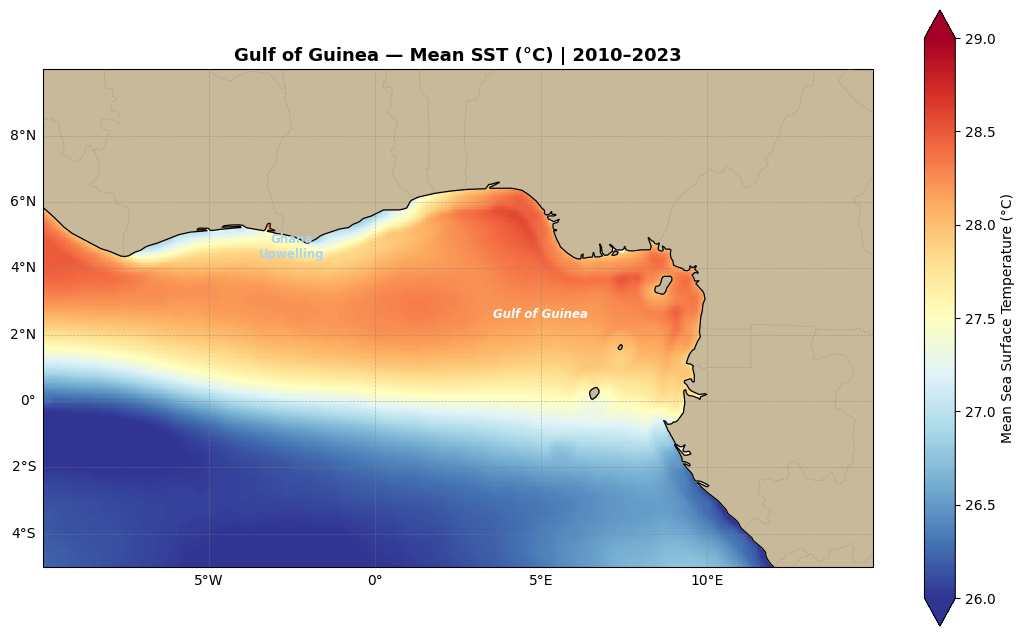

==> Saved: Day1_SST_mean_map.png
   Regional mean SST: 27.17 °C

###########> Gallery Walk: share this map when your Subgroup Instructor asks.


In [28]:
# ============================================================
# MAP 1: TIME-AVERAGED SST
# ─────────────────────────────────────────────────────────────
# .mean('time') averages all 14 years → climatological SST.
# Reveals persistent features: Guinea Current warmth,
# Ghana coastal upwelling cool tongue, equatorial patterns.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: share this map when your instructor asks.
# ============================================================

sst_mean = sst_celsius.mean('time')

fig, ax = plt.subplots(figsize=(11, 8), subplot_kw={'projection': ccrs.PlateCarree()})
sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=26, vmax=SST_VMAX, extend='both',
              cbar_kwargs={'label': 'Mean Sea Surface Temperature (°C)',
                           'shrink': 0.8, 'pad': 0.05},
              add_labels=False)

ax.add_feature(cfeature.COASTLINE, linewidth=0.9, color='black', zorder=3)
ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', color='gray', zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False

# Annotate key features (Lead Instructor will discuss these in gallery walk)
ax.text( 5.0, 2.5, f'{ZONE_NAME}', fontsize=8.5, color='white',
         ha='center', style='italic', fontweight='bold', transform=ccrs.PlateCarree())
ax.text(-2.5, 4.3, 'Ghana\nUpwelling', fontsize=8.5, color='#a8d5f0',
         ha='center', fontweight='bold', transform=ccrs.PlateCarree())

ax.set_title(f'Gulf of Guinea — Mean SST (°C) | {DATE_START[:4]}–{DATE_END[:4]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR+'/Day1_SST_mean_map.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'==> Saved: Day1_SST_mean_map.png')
print(f'   Regional mean SST: {float(sst_mean.mean().values):.2f} °C')
print()
print('###########> Gallery Walk: share this map when your Subgroup Instructor asks.')

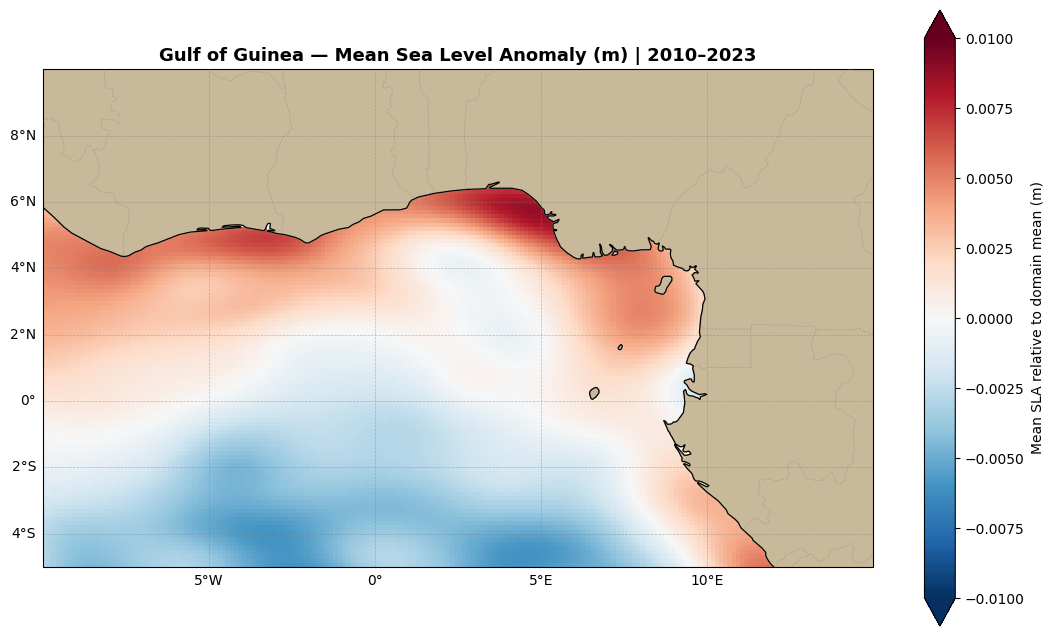

==> Saved: Day1_SSH_mean_map.png

 Annotation guide for Gallery Walk:
   Red (positive SLA)  → persistent above-average sea level → anti-cyclonic circulation
   Blue (negative SLA) → persistent below-average sea level → cyclonic / upwelling zone


In [32]:
# ============================================================
# MAP 2: TIME-AVERAGED SSH (Sea Level Anomaly)
# ─────────────────────────────────────────────────────────────
# Time-mean SLA shows persistent mesoscale circulation.
# Connect to MOOC Module 6: reading SSH forecast products.
# ============================================================

sla_raw  = ds_ssh['sla'].mean('time').compute()
sla_mean = sla_raw - sla_raw.mean()        # relative to this domain

fig, ax = plt.subplots(figsize=(11, 8), subplot_kw={'projection': ccrs.PlateCarree()})
sla_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdBu_r',
              vmin=-0.01, vmax=0.01, extend='both',
              cbar_kwargs={'label': 'Mean SLA relative to domain mean (m)',
                           'shrink': 0.8})

ax.add_feature(cfeature.COASTLINE, linewidth=0.9, color='black', zorder=3)
ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', color='gray', zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False

ax.set_title(f'Gulf of Guinea — Mean Sea Level Anomaly (m) | {DATE_START[:4]}–{DATE_END[:4]}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR+'/Day1_SSH_mean_map.png', dpi=150, bbox_inches='tight')
plt.show()
print('==> Saved: Day1_SSH_mean_map.png')
print()
print(' Annotation guide for Gallery Walk:')
print('   Red (positive SLA)  → persistent above-average sea level → anti-cyclonic circulation')
print('   Blue (negative SLA) → persistent below-average sea level → cyclonic / upwelling zone')

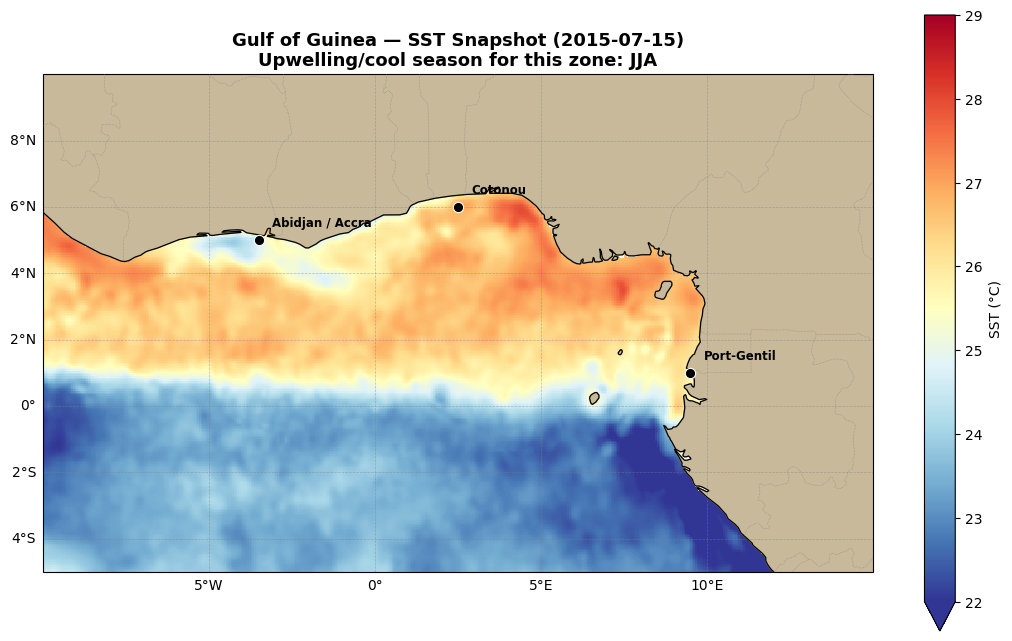

==> Saved: Day1_SST_snapshot_2015-07-15.png

==> Gallery Walk annotation points:
   • Cold patch off Ghana coast → wind-driven Ekman upwelling
   • Warm tongue along equator → Guinea Current
   • Compare with mean map: how anomalous is this July?


In [30]:
# ============================================================
# MAP 3: SST SNAPSHOT — JULY 2015
# ─────────────────────────────────────────────────────────────
# July is the peak of the West African boreal upwelling season.
# Trade winds intensify → Ekman transport → coastal cold SST.
# .sel(method='nearest') finds the closest available date.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: this map illustrates seasonal signals.
# ============================================================

sst_snap = sst_celsius.sel(time='2015-07-15', method='nearest')
actual   = str(sst_snap.time.values)[:10]

fig, ax = plt.subplots(figsize=(11, 8), subplot_kw={'projection': ccrs.PlateCarree()})
sst_snap.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=SNAP_VMIN, vmax=SNAP_VMAX,
              cbar_kwargs={'label': 'SST (°C)', 'shrink': 0.8},
              add_labels=False)

ax.add_feature(cfeature.COASTLINE, linewidth=0.9, color='black', zorder=3)
ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', color='gray', zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False

ax.set_title(f'{ZONE_NAME} — SST Snapshot ({actual})\n'
             f'Upwelling/cool season for this zone: {Z["upwell_season"]}',
             fontsize=13, fontweight='bold')

# Subgroup reference cities
for lon, lat, label in [(p[0], p[1], p[2].split('(')[0].strip()) for p in REF_POINTS]:
    ax.scatter(lon, lat, s=55, color='black', edgecolor='white', lw=0.8,
               transform=ccrs.PlateCarree(), zorder=5)
    ax.text(lon + 0.4, lat + 0.4, label, fontsize=8.5, fontweight='bold',
            transform=ccrs.PlateCarree(), zorder=6)

plt.tight_layout()
plt.savefig(OUTPUT_DIR+'/Day1_SST_snapshot_{actual}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'==> Saved: Day1_SST_snapshot_{actual}.png')
print()
print('==> Gallery Walk annotation points:')
print('   • Cold patch off Ghana coast → wind-driven Ekman upwelling')
print('   • Warm tongue along equator → Guinea Current')
print('   • Compare with mean map: how anomalous is this July?')

---

## Map 4: Wind Over SST — Forcing and Response Together

*within Independent Work Block  |  16:20–17:20*


This is the map that ties the workshop back to the MOOC.

**Colour** is sea surface temperature — the ocean's response.
**Arrows** are the mean wind — the forcing that produced it.

What to look for depends on your zone, and the differences are the point:

| Zone | What the wind is doing |
|------|------------------------|
| **1 — Mauritania / Senegal** | Northeasterly trades blow *along* the coast. Ekman transport carries surface water offshore, cold water rises to replace it. Expect the arrows to run parallel to the shore and the coldest water hard against the coast. |
| **2 — Gulf of Guinea** | Monsoon southwesterlies. But you are near the equator, where the Coriolis parameter vanishes — so the neat Ekman picture does **not** apply. Cold tongues here need a different explanation. |
| **3 — Agulhas** | Strong westerlies, but the Agulhas is an inertial western boundary current. The wind is not driving it locally. Strong wind, and the SST pattern owes it almost nothing. |

> **The question to bring to the plenary:** same physics, same product, three completely different relationships between wind and SST. Why?

---


   WIND: 1 file, 4 MB  [staged]
Wind variables: ['u10', 'v10']


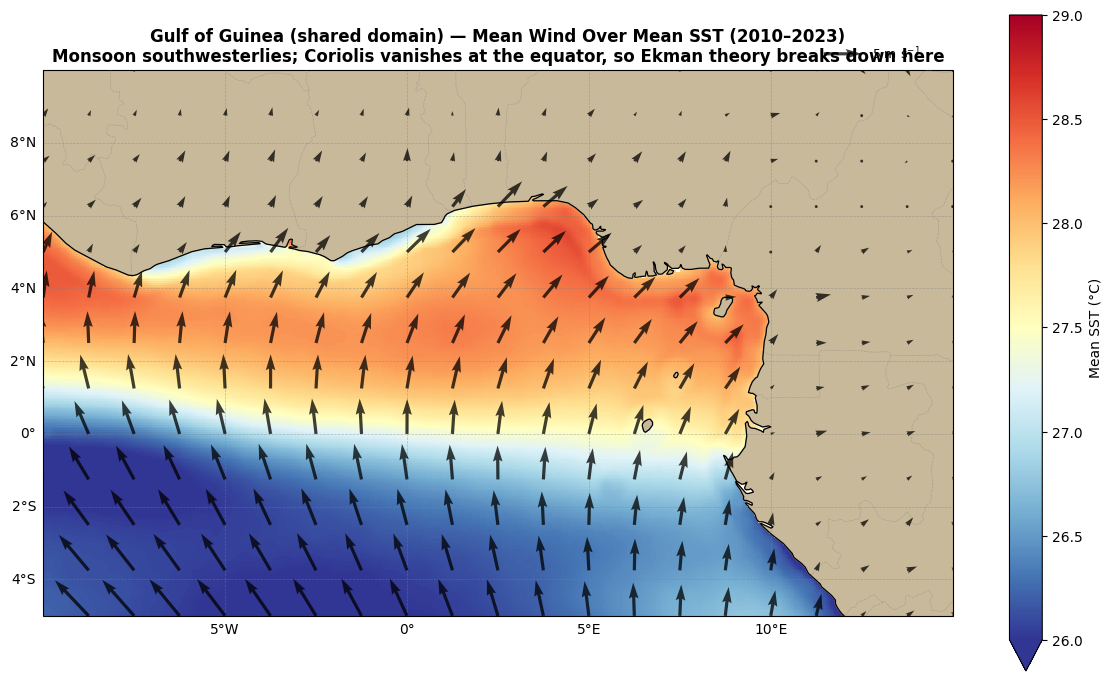


   Mean wind speed over domain : 2.88 m/s
   Maximum mean wind speed     : 6.57 m/s

   Compare with your subgroup: is the wind blowing ALONG your coast
   or ONTO it? That single question decides whether you get upwelling.


In [36]:
# ============================================================
# MAP 4: MEAN WIND VECTORS OVER MEAN SST
# ─────────────────────────────────────────────────────────────
# Two datasets on one figure. Note the regridding step: wind is
# 0.25 deg, SST is finer, so we subsample the wind grid rather
# than interpolating — quiver plots become unreadable if you
# draw an arrow at every point.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: this is the map to discuss with your subgroup.
# ============================================================

ds_wind = open_product('WIND')
print('Wind variables:', list(ds_wind.data_vars))

# Mean over the whole record
u_all, v_all = wind_components(ds_wind)     # handles ERA5 or CMEMS
u_mean = u_all.mean('time')
v_mean = v_all.mean('time')
wind_speed = (u_mean**2 + v_mean**2)**0.5

# Subsample so the arrows stay readable (aim for ~20 across)
step = max(1, len(u_mean.longitude) // 20)
u_q = u_mean.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
v_q = v_mean.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
fig, ax = plt.subplots(figsize=(12, 8.5), subplot_kw={'projection': ccrs.PlateCarree()})

# SST underneath
sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=26, vmax=SST_VMAX,
              cbar_kwargs={'label': 'Mean SST (°C)', 'shrink': 0.8, 'pad': 0.05},
              add_labels=False, zorder=1)

# Wind arrows on top
q = ax.quiver(u_q.longitude.values, u_q.latitude.values,
              u_q.values, v_q.values,
              transform=ccrs.PlateCarree(),
              scale=120, width=0.0035, color='black', alpha=0.75, zorder=4)
ax.quiverkey(q, 0.90, 1.03, 5, '5 m s$^{-1}$', labelpos='E',
             coordinates='axes', fontproperties={'size': 9})

ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, color='black', zorder=3)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', color='gray', zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False

ax.set_title(f'{DOMAIN_NAME} — Mean Wind Over Mean SST (2010–2023)\n'
             f'{Z["wind_story"]}',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + f'/Day1_wind_over_SST_{FILE_PREFIX}.png', dpi=150, bbox_inches='tight')
plt.show()

print()
print(f'   Mean wind speed over domain : {float(wind_speed.mean()):.2f} m/s')
print(f'   Maximum mean wind speed     : {float(wind_speed.max()):.2f} m/s')
print()
print('   Compare with your subgroup: is the wind blowing ALONG your coast')
print('   or ONTO it? That single question decides whether you get upwelling.')


   CURR: 1 file, 614 MB  [staged]
Current variables: ['uo', 'vo', 'ue', 've', 'ugos', 'vgos']
Dimensions of uo : ('time', 'depth', 'latitude', 'longitude')
Depth levels     : 2  -> using 0.00 m

Computing means...
Done. Field shape (60, 100), dims ('latitude', 'longitude')


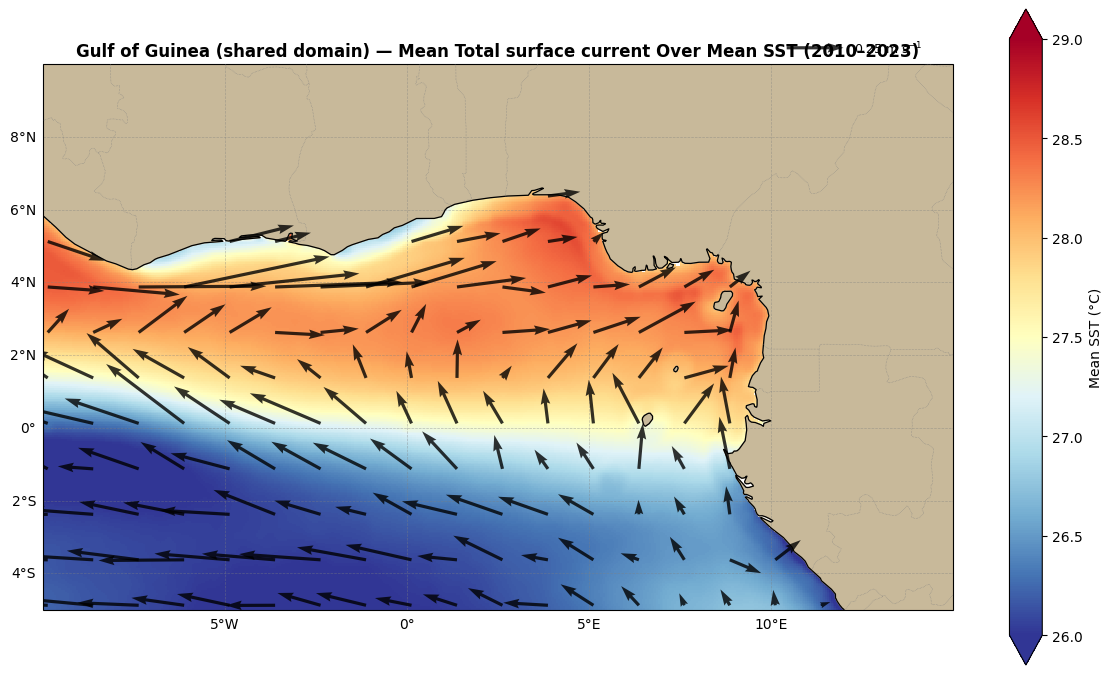


   Mean current speed over domain : 22.9 cm/s
   Maximum mean current speed     : 66.2 cm/s

   Now change COMPONENT above and re-run:
     ekman       -> should resemble your wind map (Map 4)
     geostrophic -> should follow your SLA gradients (Map 2)
   Total is roughly the sum of the two. Which dominates where?


In [40]:
# ============================================================
# MAP 5: MEAN SURFACE CURRENTS OVER MEAN SST
# ─────────────────────────────────────────────────────────────
# Same idea as Map 4, but the arrows are now the OCEAN's own
# motion rather than the wind above it.
#
# The currents file holds three decompositions of the same flow.
# Switch COMPONENT below to see each one:
#   'total'       uo / vo       everything combined
#   'ekman'       ue / ve       the part the wind drives directly
#   'geostrophic' ugos / vgos   the part pressure gradients drive
#
# NOTE ON DIMENSIONS
# SST and SSH are 2-D fields (time, lat, lon). Currents are 3-D:
# they carry a depth axis even when only the surface layer is
# supplied. quiver() needs 2-D arrays, so we select the surface
# level explicitly before plotting.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: this is the map to discuss with your subgroup.
# ============================================================

COMPONENT = 'total'          # 'total' | 'ekman' | 'geostrophic'

PAIRS = {'total':       ('uo',   'vo',   'Total surface current'),
         'ekman':       ('ue',   've',   'Ekman current — wind-driven'),
         'geostrophic': ('ugos', 'vgos', 'Geostrophic current — pressure-driven')}

un, vn, label = PAIRS[COMPONENT]

ds_curr = open_product('CURR')
print('Current variables:', list(ds_curr.data_vars))
print('Dimensions of uo :', ds_curr['uo'].dims)
if 'depth' in ds_curr.coords:
    print(f'Depth levels     : {ds_curr.depth.size}  -> using '
          f'{float(ds_curr.depth.values.flat[0]):.2f} m')
print()


def surface_mean(varname):
    """Time-mean of the surface layer, returned as a 2-D (lat, lon) field."""
    da = ds_curr[varname]
    if 'depth' in da.dims:
        da = da.isel(depth=0)          # surface layer, explicitly
    return da.mean('time').squeeze(drop=True).compute()


# Mean over the whole record (computed once — this is the slow step)
print('Computing means...')
u_mean = surface_mean(un)
v_mean = surface_mean(vn)
cur_speed = (u_mean**2 + v_mean**2)**0.5
print(f'Done. Field shape {u_mean.shape}, dims {u_mean.dims}')

# Subsample so the arrows stay readable (aim for ~20 across)
step = max(1, len(u_mean.longitude) // 20)
u_q = u_mean.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
v_q = v_mean.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))

fig, ax = plt.subplots(figsize=(12, 8.5), subplot_kw={'projection': ccrs.PlateCarree()})

# SST underneath
sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
              vmin=26, vmax=SST_VMAX, extend='both',
              cbar_kwargs={'label': 'Mean SST (°C)', 'shrink': 0.8, 'pad': 0.05},
              add_labels=False, zorder=1)

# Current arrows on top
q = ax.quiver(u_q.longitude.values, u_q.latitude.values,
              u_q.values, v_q.values,
              transform=ccrs.PlateCarree(),
              scale=4.0, width=0.0035, color='black', alpha=0.8, zorder=4)
ax.quiverkey(q, 0.88, 1.03, 0.25, '0.25 m s$^{-1}$', labelpos='E',
             coordinates='axes', fontproperties={'size': 9})

ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
ax.add_feature(cfeature.COASTLINE, linewidth=0.9, color='black', zorder=3)
ax.add_feature(cfeature.BORDERS,   linewidth=0.4, linestyle=':', color='gray', zorder=3)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color='gray', alpha=0.5, linestyle='--')
gl.top_labels = False; gl.right_labels = False

ax.set_title(f'{DOMAIN_NAME} — Mean {label} Over Mean SST (2010–2023)',
             fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + f'/Day1_{COMPONENT}_current_over_SST_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print()
print(f'   Mean current speed over domain : {float(cur_speed.mean())*100:.1f} cm/s')
print(f'   Maximum mean current speed     : {float(cur_speed.max())*100:.1f} cm/s')
print()
print('   Now change COMPONENT above and re-run:')
print('     ekman       -> should resemble your wind map (Map 4)')
print('     geostrophic -> should follow your SLA gradients (Map 2)')
print('   Total is roughly the sum of the two. Which dominates where?')
ds_curr.close()

   CURR: 1 file, 614 MB  [staged]
Current variables: ['uo', 'vo', 'ue', 've', 'ugos', 'vgos']
Dimensions of uo : ('time', 'depth', 'latitude', 'longitude')
Depth levels     : 2  -> using 0.00 m

Computing current means (this is the slow step)...
Done. Field shape (60, 100), dims ('latitude', 'longitude')



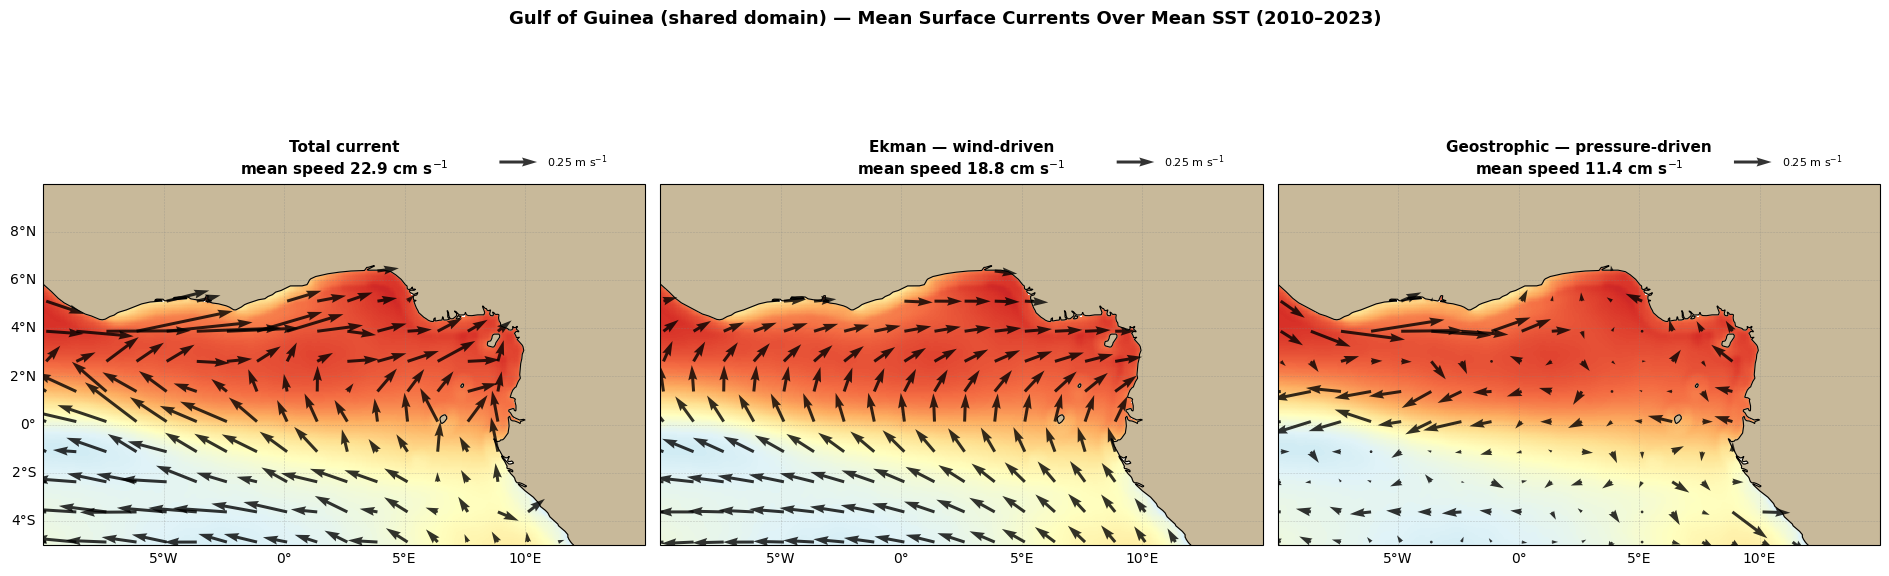


   What to look for:
   • Total ≈ Ekman + geostrophic. Which one dominates where?
   • Ekman should follow the wind map you just made — check it.
   • Geostrophic should follow the SLA gradients — check that too.
   • At the equator Ekman theory breaks down. Does the Ekman
     panel look trustworthy there?


In [39]:
# ============================================================
# MAP 6: SURFACE CURRENTS OVER SST — TOTAL, EKMAN, GEOSTROPHIC
# ─────────────────────────────────────────────────────────────
# The currents file holds three decompositions of the same flow:
#   uo / vo      total surface current
#   ue / ve      Ekman part      — driven directly by the wind
#   ugos / vgos  geostrophic part — driven by pressure gradients
#
# Plotting them separately answers a question you cannot ask of
# the total alone: WHICH part of this flow does the wind drive?
#
# NOTE ON DIMENSIONS
# SST and SSH are 2-D fields (time, lat, lon). Currents are 3-D:
# they carry a depth axis even when only the surface layer is
# supplied. quiver() needs 2-D arrays, so we select the surface
# level explicitly before plotting.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: compare the three panels.
# ============================================================

ds_curr = open_product('CURR')
print('Current variables:', list(ds_curr.data_vars))
print('Dimensions of uo :', ds_curr['uo'].dims)
if 'depth' in ds_curr.coords:
    print(f'Depth levels     : {ds_curr.depth.size}  -> using '
          f'{float(ds_curr.depth.values.flat[0]):.2f} m')
print()

COMPONENTS = [('uo',   'vo',   'Total current'),
              ('ue',   've',   'Ekman — wind-driven'),
              ('ugos', 'vgos', 'Geostrophic — pressure-driven')]


def surface_mean(varname):
    """Time-mean of the surface layer, returned as a 2-D (lat, lon) field."""
    da = ds_curr[varname]
    if 'depth' in da.dims:
        da = da.isel(depth=0)          # surface layer, explicitly
    return da.mean('time').squeeze(drop=True).compute()


print('Computing current means (this is the slow step)...')
means = []
for un, vn, label in COMPONENTS:
    u = surface_mean(un)
    v = surface_mean(vn)
    means.append((u, v, label))
print(f'Done. Field shape {means[0][0].shape}, dims {means[0][0].dims}\n')

fig, axes = plt.subplots(1, 3, figsize=(19, 6.5),
                         subplot_kw={'projection': ccrs.PlateCarree()})

for ax, (u, v, label) in zip(axes, means):
    sst_mean.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
                  vmin=26, vmax=SST_VMAX, extend='both',
                  add_colorbar=False, add_labels=False, zorder=1)

    step = max(1, len(u.longitude) // 18)
    uq = u.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    spd = float(((u**2 + v**2)**0.5).mean())

    q = ax.quiver(uq.longitude.values, uq.latitude.values,
                  uq.values, vq.values,
                  transform=ccrs.PlateCarree(), scale=4.0, width=0.005,
                  color='black', alpha=0.8, zorder=4)
    ax.quiverkey(q, 0.82, 1.06, 0.25, '0.25 m s$^{-1}$', labelpos='E',
                 coordinates='axes', fontproperties={'size': 8})

    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False
    if ax is not axes[0]:
        gl.left_labels = False

    ax.set_title(f'{label}\nmean speed {spd*100:.1f} cm s$^{{-1}}$',
                 fontsize=11, fontweight='bold')

fig.suptitle(f'{DOMAIN_NAME} — Mean Surface Currents Over Mean SST '
             f'({DATE_START[:4]}–{DATE_END[:4]})',
             fontsize=13, fontweight='bold', y=1.02)

plt.tight_layout()
plt.savefig(OUTPUT_DIR + f'/Day1_currents_over_SST_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print()
print('   What to look for:')
print('   • Total ≈ Ekman + geostrophic. Which one dominates where?')
print('   • Ekman should follow the wind map you just made — check it.')
print('   • Geostrophic should follow the SLA gradients — check that too.')
print('   • At the equator Ekman theory breaks down. Does the Ekman')
print('     panel look trustworthy there?')
ds_curr.close()

   WIND: 1 file, 4 MB  [staged]
   SST: 1 file, 1534 MB  [staged]
Computing seasonal wind and SST means...
   DJF done — mean wind 2.51 m/s
   MAM done — mean wind 2.80 m/s
   JJA done — mean wind 3.60 m/s
   SON done — mean wind 3.03 m/s



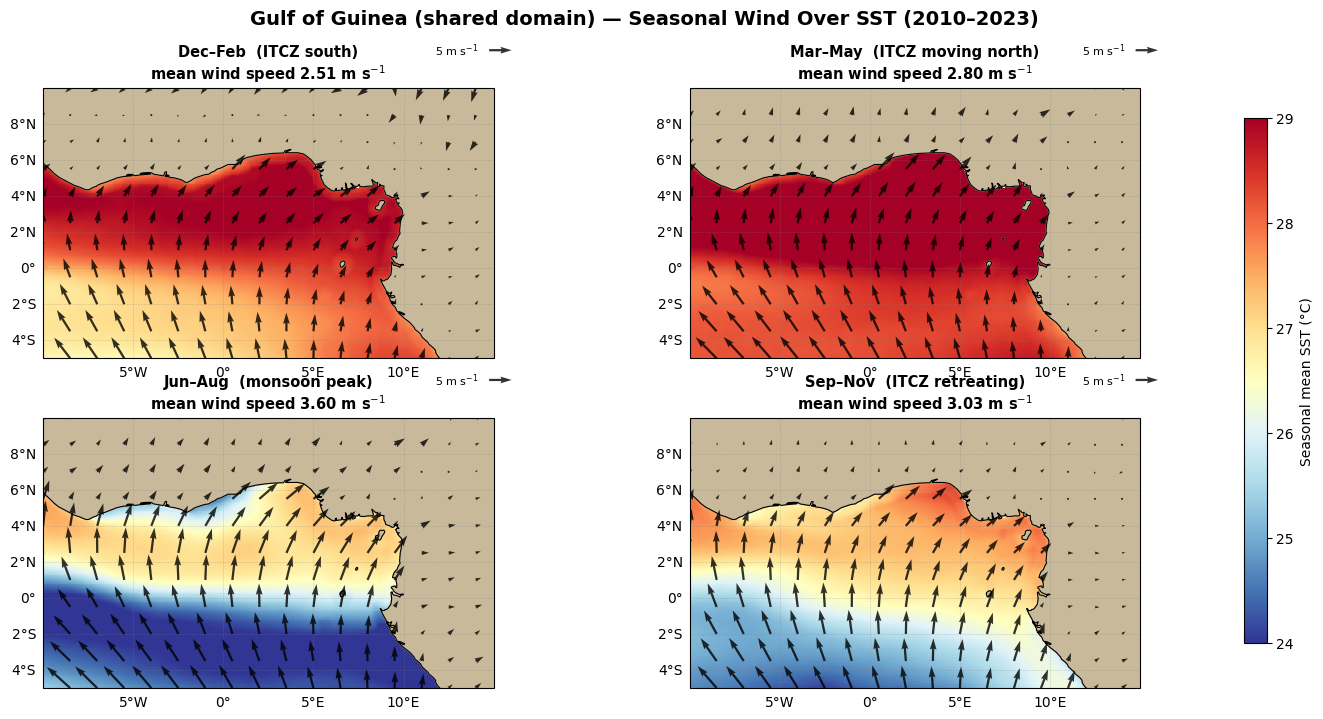


   FORCING AND RESPONSE — compare with Map 7:
     DJF   wind  2.51 m/s
     MAM   wind  2.80 m/s
     JJA   wind  3.60 m/s
     SON   wind  3.03 m/s

   • Does the wind peak in the same season as the Ekman current?
   • Watch the arrows cross the equator and turn right —
     that is Coriolis changing sign, and it is the monsoon.
   • Arrows continue over land. ERA5 is atmospheric, so it has
     wind everywhere. CMEMS would give you nothing over Burkina Faso.


In [51]:
# ============================================================
# MAP 7: SEASONAL WIND OVER SST — THE MONSOON CYCLE ITSELF
# ─────────────────────────────────────────────────────────────
# Map 8 showed the OCEAN's seasonal response (Ekman currents).
# This shows the ATMOSPHERIC FORCING that produced it.
#
# Run them side by side. The Ekman currents peaked in JJA at
# 23.9 cm/s — if the wind does the same, you have measured a
# cause and its effect with two independent products from two
# different services.
#
# THE MONSOON, IN FOUR PANELS
# The ITCZ migrates north in boreal summer. Southeast trades
# cross the equator, are deflected right by Coriolis, and
# arrive over West Africa as southwesterlies carrying the rains.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: compare this with Map 8 — forcing and response.
# ============================================================

ds_wind_s = open_product('WIND')
ds_sst_s  = open_product('SST')

SEASONS = [('DJF', 'Dec–Feb  (ITCZ south)'),
           ('MAM', 'Mar–May  (ITCZ moving north)'),
           ('JJA', 'Jun–Aug  (monsoon peak)'),
           ('SON', 'Sep–Nov  (ITCZ retreating)')]

# normalise ERA5 naming (valid_time -> time) before grouping
u_all, v_all = wind_components(ds_wind_s)


def seasonal_wind(da, season):
    return (da.groupby('time.season').mean('time')
              .sel(season=season).squeeze(drop=True).compute())


def seasonal_sst(season):
    da = ds_sst_s['analysed_sst']
    return (da.groupby('time.season').mean('time')
              .sel(season=season).squeeze(drop=True).compute()) - 273.15


print('Computing seasonal wind and SST means...')
panels = []
for code, title in SEASONS:
    u_s   = seasonal_wind(u_all, code)
    v_s   = seasonal_wind(v_all, code)
    sst_s = seasonal_sst(code)
    spd   = float(((u_s**2 + v_s**2)**0.5).mean())
    panels.append((u_s, v_s, sst_s, code, title, spd))
    print(f'   {code} done — mean wind {spd:.2f} m/s')
print()

fig, axes = plt.subplots(2, 2, figsize=(15, 7.5),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         gridspec_kw={'wspace': 0.08, 'hspace': 0.22})

for ax, (u, v, sst_s, code, title, spd) in zip(axes.flat, panels):
    im = sst_s.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
                    vmin=24, vmax=SNAP_VMAX, extend='both',
                    add_colorbar=False, add_labels=False, zorder=1)

    step = max(1, len(u.longitude) // 16)
    uq = u.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))

    q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
                  transform=ccrs.PlateCarree(), scale=100, width=0.005,
                  color='black', alpha=0.8, zorder=4)
    ax.quiverkey(q, 0.99, 1.14, 5, '5 m s$^{-1}$', labelpos='W',
                 coordinates='axes', fontproperties={'size': 8})

    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False

    ax.set_title(f'{title}\nmean wind speed {spd:.2f} m s$^{{-1}}$',
                 fontsize=10.5, fontweight='bold')

fig.subplots_adjust(left=0.05, right=0.88, top=0.86, bottom=0.06)
cax = fig.add_axes([0.90, 0.12, 0.015, 0.70])
fig.colorbar(im, cax=cax, label='Seasonal mean SST (°C)')

fig.suptitle(f'{DOMAIN_NAME} — Seasonal Wind Over SST '
             f'({DATE_START[:4]}–{DATE_END[:4]})',
             fontsize=14, fontweight='bold', y=0.965)

plt.savefig(OUTPUT_DIR + f'/Day1_seasonal_wind_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print()
print('   FORCING AND RESPONSE — compare with Map 7:')
for _, _, _, code, _, spd in panels:
    print(f'     {code}   wind {spd:>5.2f} m/s')
print()
print('   • Does the wind peak in the same season as the Ekman current?')
print('   • Watch the arrows cross the equator and turn right —')
print('     that is Coriolis changing sign, and it is the monsoon.')
print('   • Arrows continue over land. ERA5 is atmospheric, so it has')
print('     wind everywhere. CMEMS would give you nothing over Burkina Faso.')
ds_wind_s.close()
ds_sst_s.close()

   CURR: 1 file, 614 MB  [staged]
   SST: 1 file, 1534 MB  [staged]
Computing seasonal means (slow — four seasons, three fields)...
   DJF done — mean Ekman 15.4 cm/s
   MAM done — mean Ekman 17.6 cm/s
   JJA done — mean Ekman 23.9 cm/s
   SON done — mean Ekman 19.0 cm/s



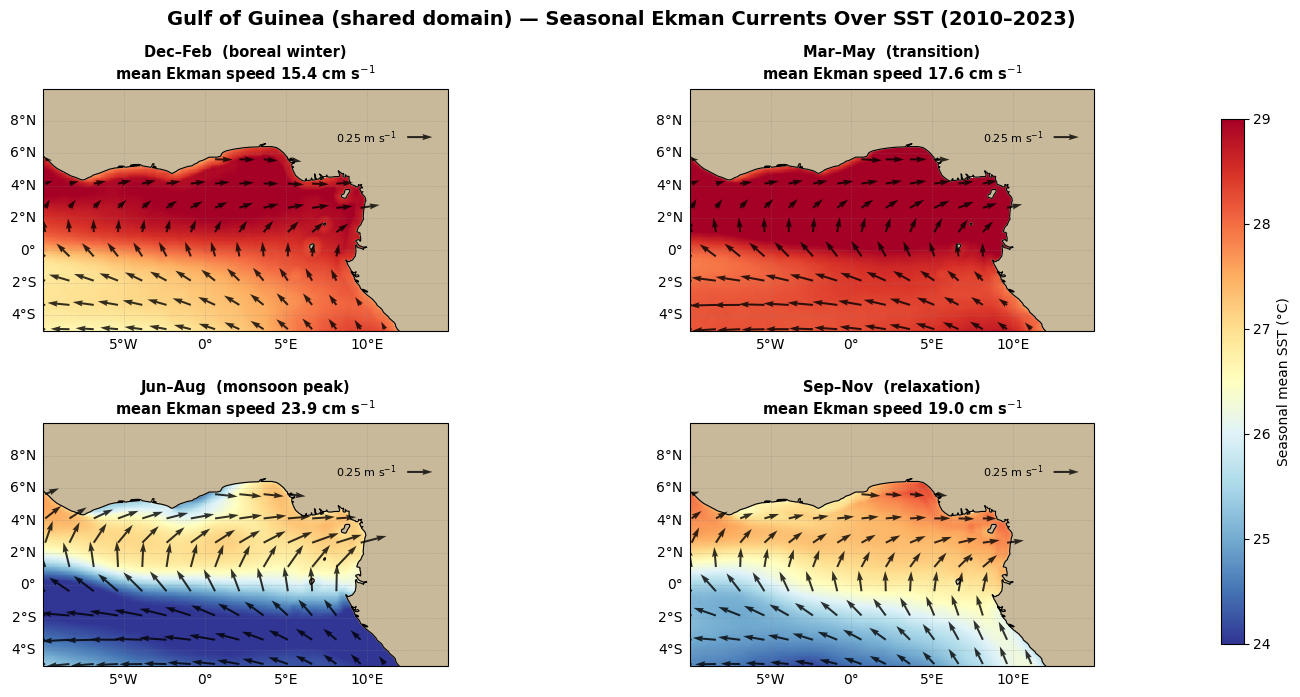


   Seasonal cycle of the Ekman response:
     DJF    15.4 cm/s  #######
     MAM    17.6 cm/s  ########
     JJA    23.9 cm/s  ###########
     SON    19.0 cm/s  #########

   What to look for:
   • Compare DJF and JJA. How much does the Ekman flow change?
   • The cold tongue appears in one season and fades in another.
     Does the Ekman flow strengthen at the same time?
   • Southern hemisphere zones: JJA is your WINTER, not summer.
   • Which season would matter most to a fisher on your coast?


In [49]:
# ============================================================
# MAP 8: SEASONAL EKMAN CURRENTS — THE MONSOON CYCLE
# ─────────────────────────────────────────────────────────────
# Map 6 showed 14-year means. Means hide seasons.
#
# The Ekman component is wind-driven, so it should swing with
# the monsoon: the ITCZ migrates north in boreal summer, the
# southwesterlies strengthen, and the equatorial cold tongue
# develops. Four seasonal panels make that visible.
#
# Watch JJA in particular — the cold tongue at its strongest.
# ─────────────────────────────────────────────────────────────
# Gallery Walk: which season drives your coast hardest?
# ============================================================

ds_curr  = open_product('CURR')
ds_sst_s = open_product('SST')

SEASONS = [('DJF', 'Dec–Feb  (boreal winter)'),
           ('MAM', 'Mar–May  (transition)'),
           ('JJA', 'Jun–Aug  (monsoon peak)'),
           ('SON', 'Sep–Nov  (relaxation)')]


def seasonal_surface(varname, ds, season):
    """Seasonal mean of the surface layer, as a 2-D (lat, lon) field."""
    da = ds[varname]
    if 'depth' in da.dims:
        da = da.isel(depth=0)
    return (da.groupby('time.season')
              .mean('time')
              .sel(season=season)
              .squeeze(drop=True)
              .compute())


print('Computing seasonal means (slow — four seasons, three fields)...')
panels = []
for code, title in SEASONS:
    ue_s  = seasonal_surface('ue', ds_curr, code)
    ve_s  = seasonal_surface('ve', ds_curr, code)
    sst_s = seasonal_surface('analysed_sst', ds_sst_s, code) - 273.15
    spd   = float(((ue_s**2 + ve_s**2)**0.5).mean())
    panels.append((ue_s, ve_s, sst_s, code, title, spd))
    print(f'   {code} done — mean Ekman {spd*100:.1f} cm/s')
print()

# Wide-and-short domain, so keep the figure short or you get dead space
fig, axes = plt.subplots(2, 2, figsize=(15, 7.5),
                         subplot_kw={'projection': ccrs.PlateCarree()},
                         gridspec_kw={'wspace': 0.08, 'hspace': 0.38})

for ax, (u, v, sst_s, code, title, spd) in zip(axes.flat, panels):
    im = sst_s.plot(ax=ax, transform=ccrs.PlateCarree(), cmap='RdYlBu_r',
                    vmin=24, vmax=SNAP_VMAX, extend='both',
                    add_colorbar=False, add_labels=False, zorder=1)

    step = max(1, len(u.longitude) // 16)
    uq = u.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))
    vq = v.isel(longitude=slice(None, None, step), latitude=slice(None, None, step))

    q = ax.quiver(uq.longitude.values, uq.latitude.values, uq.values, vq.values,
                  transform=ccrs.PlateCarree(), scale=4.0, width=0.005,
                  color='black', alpha=0.8, zorder=4)
    # key INSIDE the panel, bottom right — cannot collide with titles
    ax.quiverkey(q, 0.9, 0.8, 0.25, '0.25 m s$^{-1}$', labelpos='W',
                 coordinates='axes', fontproperties={'size': 8})

    ax.add_feature(cfeature.LAND,      color='#C8B99A', zorder=2)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8, zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color='gray',
                      alpha=0.4, linestyle='--')
    gl.top_labels = False; gl.right_labels = False

    ax.set_title(f'{title}\nmean Ekman speed {spd*100:.1f} cm s$^{{-1}}$',
                 fontsize=10.5, fontweight='bold')

# Manual layout — no tight_layout(), it fights with placed axes
fig.subplots_adjust(left=0.05, right=0.88, top=0.86, bottom=0.09)

# Colorbar in its own slot rather than carved out of the panels
cax = fig.add_axes([0.90, 0.12, 0.015, 0.70])   # [left, bottom, width, height]
fig.colorbar(im, cax=cax, label='Seasonal mean SST (°C)')

fig.suptitle(f'{DOMAIN_NAME} — Seasonal Ekman Currents Over SST '
             f'({DATE_START[:4]}–{DATE_END[:4]})',
             fontsize=14, fontweight='bold', y=0.965)

plt.savefig(OUTPUT_DIR + f'/Day1_seasonal_ekman_{FILE_PREFIX}.png',
            dpi=150, bbox_inches='tight')
plt.show()

print()
print('   Seasonal cycle of the Ekman response:')
for _, _, _, code, _, spd in panels:
    bar = '#' * int(spd * 100 / 2)
    print(f'     {code}   {spd*100:>5.1f} cm/s  {bar}')
print()
print('   What to look for:')
print('   • Compare DJF and JJA. How much does the Ekman flow change?')
print('   • The cold tongue appears in one season and fades in another.')
print('     Does the Ekman flow strengthen at the same time?')
print('   • Southern hemisphere zones: JJA is your WINTER, not summer.')
print('   • Which season would matter most to a fisher on your coast?')
ds_curr.close()
ds_sst_s.close()

---

##  Section 7 — Time Series: Seasonal Cycles and Interannual Variability

*within Independent Work Block  |  16:20–17:20*


Maps reveal spatial structure. Time series reveal **temporal dynamics** — the seasonal signal,  
year-to-year anomalies, and long-term trends that matter for professional applications.

> **MOOC connection:** Module 2 — seasonal ocean variability and physical drivers.  
> Module 6 — interpreting variability in forecast products.  
> **Day 2 preview:** tomorrow we quantify anomalies precisely (Notebook 2).

---

   Abidjan / Accra: 27.21 -> 27.54 °C  (+0.33)
   Cotonou: 27.87 -> 28.26 °C  (+0.39)
   Port-Gentil: 27.58 -> 28.03 °C  (+0.44)


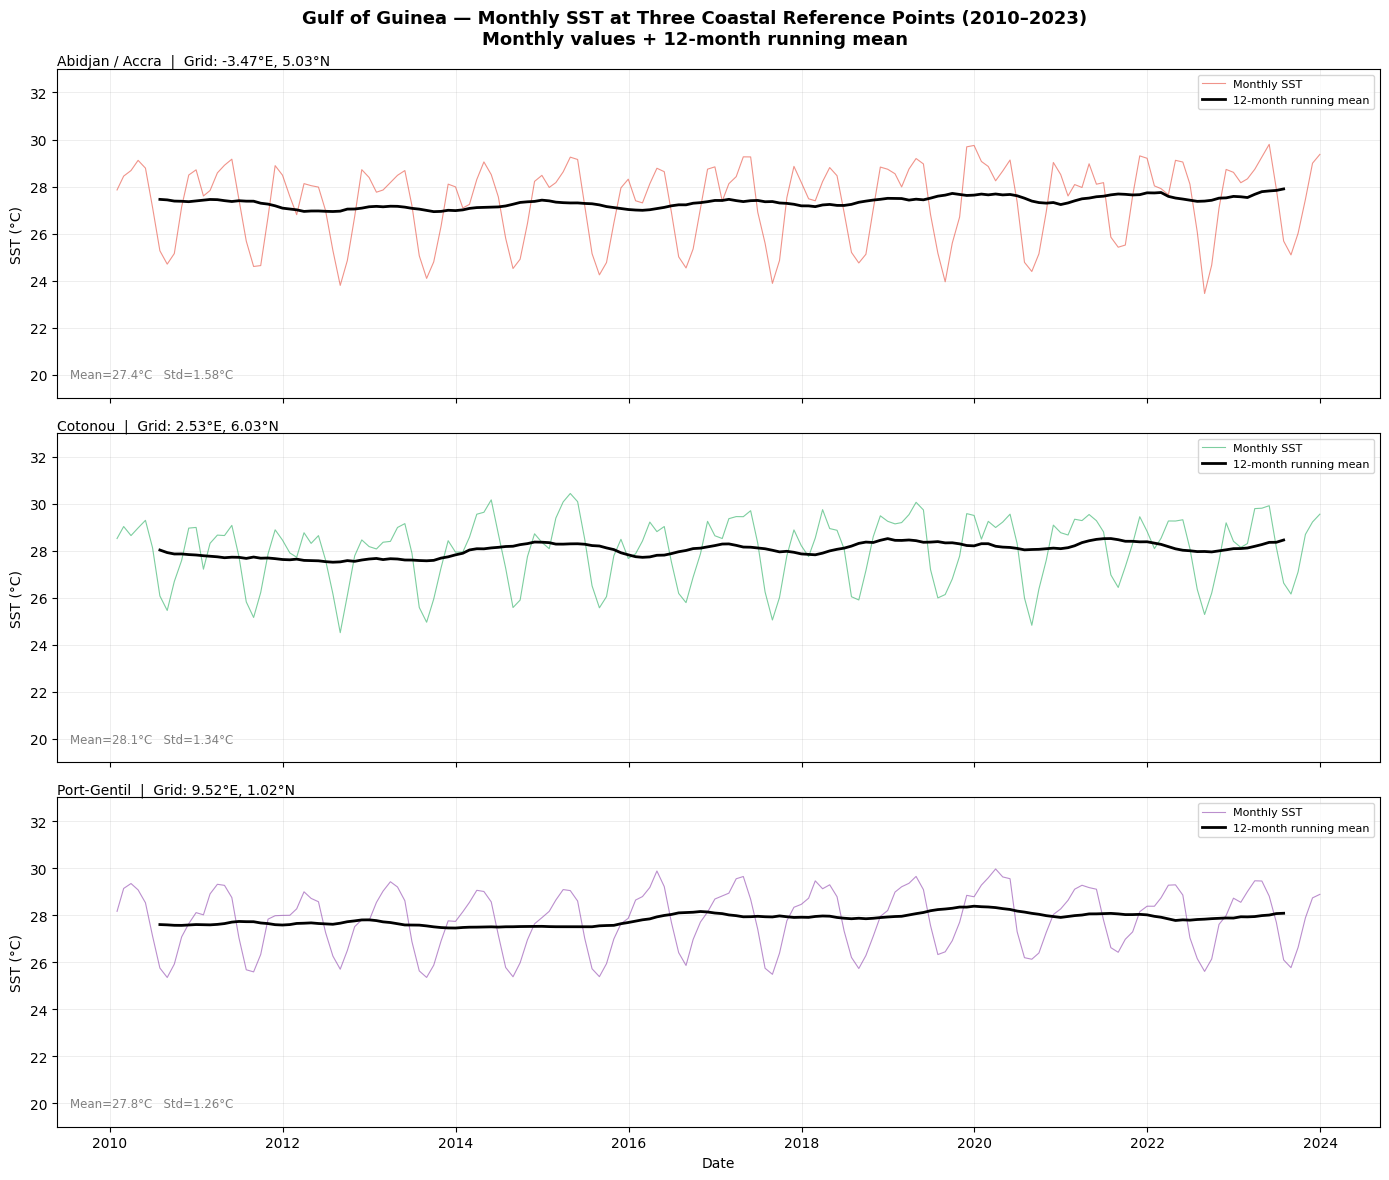

==> Saved: Day1_SST_timeseries.png


In [53]:
# ============================================================
# TIME SERIES: MONTHLY SST AT THREE COASTAL REFERENCE POINTS
# ─────────────────────────────────────────────────────────────
# Three coastal points across the domain. On Day 2 you will
# compute anomalies for the points inside your own study area.
# ============================================================

# REF_POINTS and COLORS now come from the zone config above.

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle(
    f'{ZONE_NAME} — Monthly SST at Three Coastal Reference Points (2010–2023)\n'
    'Monthly values + 12-month running mean',
    fontsize=13, fontweight='bold', y=0.98)

for ax, (lon, lat, label), color in zip(axes, REF_POINTS, COLORS):
    ts = sst_celsius.sel(longitude=lon, latitude=lat, method='nearest')
    alon = float(ts.longitude.values); alat = float(ts.latitude.values)
    ts_m = ts.to_series().resample('ME').mean()
    rmean = ts_m.rolling(12, center=True).mean()
    early = ts_m['2010':'2015'].mean()
    late  = ts_m['2018':'2023'].mean()
    print(f'   {label}: {early:.2f} -> {late:.2f} °C  ({late-early:+.2f})')

    ax.plot(ts_m.index, ts_m.values, color=color, lw=0.8, alpha=0.6, label='Monthly SST')
    ax.plot(ts_m.index, rmean,        color='black', lw=2.0,          label='12-month running mean')
    ax.set_ylabel('SST (°C)', fontsize=10)
    ax.set_title(f'{label}  |  Grid: {alon:.2f}°E, {alat:.2f}°N', fontsize=10, loc='left', pad=3)
    ax.legend(fontsize=8, loc='upper right')
    ax.set_ylim(TS_YMIN, TS_YMAX); ax.grid(True, alpha=0.3, lw=0.5)
    ax.text(0.01, 0.06, f'Mean={float(ts_m.mean()):.1f}°C   Std={float(ts_m.std()):.2f}°C',
            transform=ax.transAxes, fontsize=8.5, color='gray')

axes[-1].set_xlabel('Date', fontsize=10)
plt.tight_layout()
plt.savefig(OUTPUT_DIR+'/Day1_SST_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print('==> Saved: Day1_SST_timeseries.png')

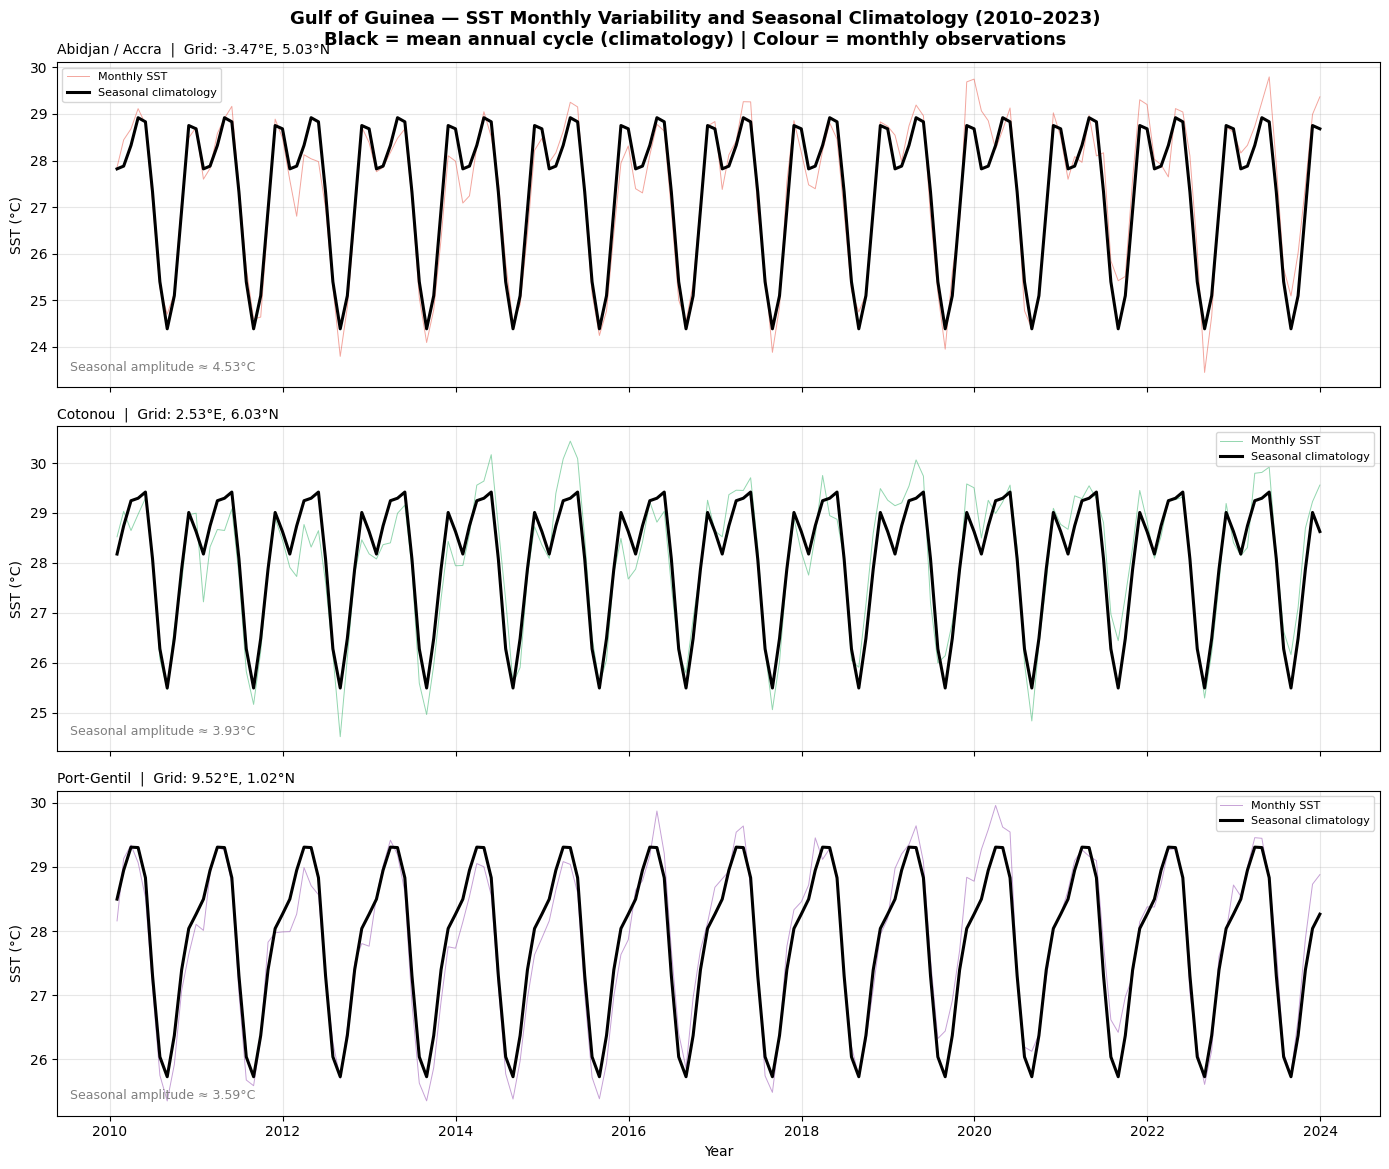

==> Saved: Day1_SST_Seasonality.png

==> Day 2 preview: Anomaly = Monthly SST − Climatology (black line)
   Positive anomaly → warmer than usual for that month
   Negative anomaly → cooler than usual → potential upwelling intensification


In [54]:
# ============================================================
# SEASONAL CLIMATOLOGY — MEAN ANNUAL CYCLE
# ─────────────────────────────────────────────────────────────
# The climatology = mean SST for each calendar month,
#                   averaged across ALL years (2010–2023).
# The coloured line = monthly observations.
# Deviation from the black line = anomaly.
# ─────────────────────────────────────────────────────────────
# Day 2 preview: Notebook 2 computes anomaly = monthly − clim.
# ============================================================

fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)
fig.suptitle(
    'Gulf of Guinea — SST Monthly Variability and Seasonal Climatology (2010–2023)\n'
    'Black = mean annual cycle (climatology) | Colour = monthly observations',
    fontsize=13, fontweight='bold', y=0.97)

for ax, (lon, lat, label), color in zip(axes, REF_POINTS, COLORS):
    ts = sst_celsius.sel(longitude=lon, latitude=lat, method='nearest')
    alon = float(ts.longitude.values); alat = float(ts.latitude.values)
    ts_m  = ts.to_series().resample('ME').mean()
    clim  = ts_m.groupby(ts_m.index.month).mean()
    scyc  = ts_m.index.month.map(clim)

    ax.plot(ts_m.index, ts_m.values, color=color, lw=0.7, alpha=0.5, label='Monthly SST')
    ax.plot(ts_m.index, scyc,        color='black', lw=2.2,           label='Seasonal climatology')
    ax.set_ylabel('SST (°C)', fontsize=10)
    ax.set_title(f'{label}  |  Grid: {alon:.2f}°E, {alat:.2f}°N', fontsize=10, loc='left')
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    ax.text(0.01, 0.05, f'Seasonal amplitude ≈ {clim.max()-clim.min():.2f}°C',
            transform=ax.transAxes, fontsize=9, color='gray')

axes[-1].set_xlabel('Year', fontsize=10)
plt.tight_layout()
plt.savefig(OUTPUT_DIR+'/Day1_SST_Seasonality.png', dpi=150, bbox_inches='tight')
plt.show()
print('==> Saved: Day1_SST_Seasonality.png')
print()
print('==> Day 2 preview: Anomaly = Monthly SST − Climatology (black line)')
print('   Positive anomaly → warmer than usual for that month')
print('   Negative anomaly → cooler than usual → potential upwelling intensification')

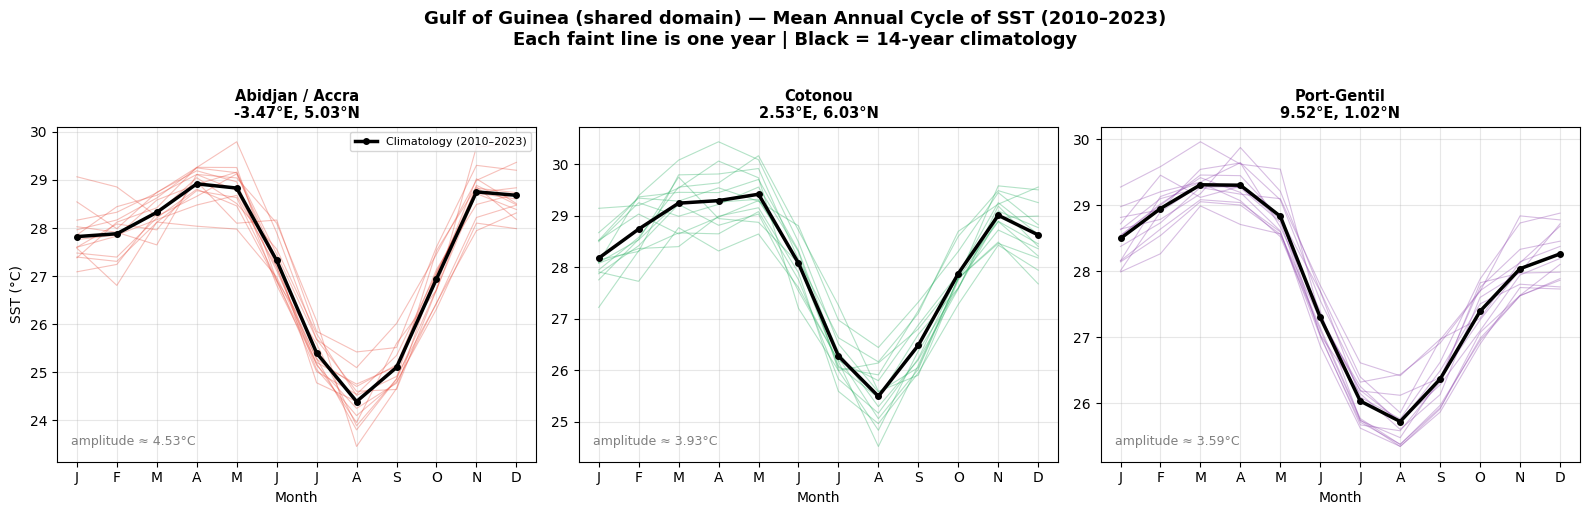

==> Saved: Day1_SST_Seasonality.png

   The SPREAD between faint lines at a given month is the
   interannual variability. Where is it widest — and why?

==> Day 2 preview: anomaly = monthly SST − climatology.
   A faint line above black = warmer than usual that month.
   A faint line below black = cooler — possible upwelling event.


In [57]:
# ============================================================
# SEASONAL CLIMATOLOGY — MEAN ANNUAL CYCLE
# ─────────────────────────────────────────────────────────────
# The climatology = mean SST for each calendar month, averaged
# across ALL years (2010–2023).
#
# Each faint line is ONE year, folded onto a single 12-month
# axis. The bold black line is the average of all of them.
#
# The SPREAD between the faint lines is interannual variability
# — the thing Day 2 measures. A year sitting well above the
# black line was anomalously warm in that month.
# ─────────────────────────────────────────────────────────────
# Day 2 preview: Notebook 2 computes anomaly = monthly − clim.
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)
fig.suptitle(
    f'{DOMAIN_NAME} — Mean Annual Cycle of SST (2010–2023)\n'
    'Each faint line is one year | Black = 14-year climatology',
    fontsize=13, fontweight='bold', y=1.02)

MONTHS = ['J','F','M','A','M','J','J','A','S','O','N','D']

for ax, (lon, lat, label), color in zip(axes, REF_POINTS, COLORS):
    ts = sst_celsius.sel(longitude=lon, latitude=lat, method='nearest')
    alon = float(ts.longitude.values); alat = float(ts.latitude.values)
    ts_m = ts.to_series().resample('ME').mean()
    clim = ts_m.groupby(ts_m.index.month).mean()

    # one faint trace per year
    for yr, grp in ts_m.groupby(ts_m.index.year):
        ax.plot(grp.index.month, grp.values, color=color, lw=0.8, alpha=0.35)

    # the climatology, once
    ax.plot(range(1, 13), clim.values, color='black', lw=2.5,
            marker='o', markersize=4, label='Climatology (2010–2023)', zorder=5)

    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.set_xlim(0.5, 12.5)
    ax.set_xlabel('Month', fontsize=10)
    ax.set_title(f'{label}\n{alon:.2f}°E, {alat:.2f}°N', fontsize=10.5,
                 fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.text(0.03, 0.05, f'amplitude ≈ {clim.max() - clim.min():.2f}°C',
            transform=ax.transAxes, fontsize=9, color='gray')

axes[0].set_ylabel('SST (°C)', fontsize=10)
axes[0].legend(fontsize=8, loc='upper right')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + '/Day1_SST_Seasonality.png', dpi=150, bbox_inches='tight')
plt.show()

print('==> Saved: Day1_SST_Seasonality.png')
print()
print('   The SPREAD between faint lines at a given month is the')
print('   interannual variability. Where is it widest — and why?')
print()
print('==> Day 2 preview: anomaly = monthly SST − climatology.')
print('   A faint line above black = warmer than usual that month.')
print('   A faint line below black = cooler — possible upwelling event.')

---

## Gallery Walk Discussion Questions

*Gallery Walk  |  17:20–17:50  (30 min — 5–6 people share)*



The Coordinator introduces each subgroup volunteer. The Lead Instructor annotates each map.  
Use these questions to guide the plenary discussion:

---

**Q1 — Where is the upwelling signature strongest?**  
Compare seasonal amplitudes across the three subgroup reference points.  
*Guide toward:* wind-driven Ekman transport · coastal geometry · Guinea Current interaction · ITCZ seasonal migration

**Q2 — Why does SST cool in July–August?**  
What atmospheric change drives this cooling?  
*Guide toward:* northward ITCZ migration · stronger SW trade winds · Ekman coastal upwelling

**Q3 — Why is the coldest water against the Angolan coast, not at the equator?**
Look at the July snapshot. Two separate mechanisms are producing similar SST.
Guide toward: coastal Ekman upwelling (alongshore wind → offshore transport → deep water rises)
vs. equatorial divergence (Coriolis changes sign across 0° → surface waters spread apart).
Same result, different physics — Gaël's Chapter 4 made both visible in one image.

**Q4 — Why do monthly observations deviate from the black climatology line?**  
*Guide toward:* interannual variability · Atlantic Niño events · marine heatwaves  
*Connect to Day 2:* these deviations are the anomalies we will compute and analyze tomorrow

**Q5 — Is there a long-term warming signal?**  
Compare 2019–2023 vs. 2010–2015.  
*Guide toward:* climate change · regional warming · implications for fisheries (Module 7 connection)

---

---

##  Section 8 — Day 1 End-of-Day Checklist

*Close  |  17:50–18:00  (10 min)*



> **Assessment guideline (Day 1):** All participants confirm environment is working and datasets accessible.  
> Run this cell before the wrap-up plenary. Everyone must pass all checks.  
> If anything fails: contact your Subgroup Instructor before leaving today.

In [58]:
# ============================================================
# DAY 1 END-OF-DAY VERIFICATION  (Everyone runs this)
# ─────────────────────────────────────────────────────────────
# Automated check: files on Drive, data physically valid,
# output maps saved. All must pass before Day 2.
# ============================================================

print('=' * 62)
print('   OPERA AIA — DAY 1 END-OF-DAY CHECKLIST')
print('=' * 62)
print()
all_ok = True

# ── 1. Files ────────────────────────────────────────────────
print(' DATASETS ON GOOGLE DRIVE:')
for label, fpath in [('SST Reanalysis NetCDF', SST_FILE),
                     ('SSH Altimetry NetCDF', SSH_FILE),
                     ('Surface Currents NetCDF', CURR_FILE)]:
    if os.path.exists(fpath):
        print(f'  ==>  {label:<28}  ({os.path.getsize(fpath)/1e6:.0f} MB)')
    else:
        print(f'  ❌  {label:<28}  — FILE NOT FOUND'); all_ok = False
print()

# ── 2. SST physically valid ─────────────────────────────────
print('==>  SST DATA VALIDATION:')
try:
    v = xr.open_dataset(SST_FILE, chunks={'time': 30}, engine='h5netcdf')['analysed_sst'] - 273.15
    mn, mx = float(v.min().values), float(v.max().values)
    if 15 < mn and mx < 35:
        print(f'  ==>  SST range plausible: {mn:.1f}°C to {mx:.1f}°C')
    else:
        print(f'  ⚠️  Unexpected SST range: {mn:.1f}°C to {mx:.1f}°C'); all_ok = False
except Exception as e:
    print(f'  ❌  Cannot open SST: {e}'); all_ok = False
print()

# ── 3. SSH physically valid ─────────────────────────────────
print('==> SSH DATA VALIDATION:')
try:
    s = xr.open_dataset(SSH_FILE, chunks={'time': 30}, engine='h5netcdf')['sla']
    mn, mx = float(s.min().values), float(s.max().values)
    if -1.0 < mn < 0 and 0 < mx < 1.0:
        print(f' ==>  SLA range plausible: {mn:.3f} m to {mx:.3f} m')
    else:
        print(f'  ⚠️  Unexpected SLA range: {mn:.3f} m to {mx:.3f} m')
except Exception as e:
    print(f'  ❌  Cannot open SSH: {e}'); all_ok = False
print()

# ── 4. Output maps saved ────────────────────────────────────
print('==>  OUTPUT MAPS:')
for fname in [OUTPUT_DIR+'/Day1_study_region_map.png', OUTPUT_DIR+'/Day1_SST_mean_map.png',
              OUTPUT_DIR+'/Day1_SSH_mean_map.png', OUTPUT_DIR+'/Day1_SST_timeseries.png',
              OUTPUT_DIR+'/Day1_SST_Seasonality.png']:
    if os.path.exists(fname):
        print(f'  ==>  {fname}')
    else:
        print(f'  ❌  {fname} — re-run the relevant plot cell'); all_ok = False
print()

# ── Result ───────────────────────────────────────────────────
print('=' * 62)
if all_ok:
    print('==? ALL CHECKS PASSED — you are ready for Day 2!')
    print()
    print('   Day 2 notebooks:')
    print('   • Notebook 1 — SST Visualization (deeper dive)')
    print('   • Notebook 2 — Anomaly Detection & Seasonal Averages')
    print('   • Subgroup analysis of your study area (set PHASE = \'zone\')')
    print()
    print('    Type "Day 1 complete" in the chat.')
else:
    print('==>  SOME CHECKS FAILED.')
    print('   Contact your Subgroup Instructor before leaving.')
    print('   Fallback datasets are on the shared cloud drive.')
print('=' * 62)

   OPERA AIA — DAY 1 END-OF-DAY CHECKLIST

 DATASETS ON GOOGLE DRIVE:
  ==>  SST Reanalysis NetCDF         (1534 MB)
  ==>  SSH Altimetry NetCDF          (982 MB)
  ==>  Surface Currents NetCDF       (614 MB)

==>  SST DATA VALIDATION:
  ==>  SST range plausible: 18.9°C to 32.9°C

==> SSH DATA VALIDATION:
 ==>  SLA range plausible: -0.088 m to 0.299 m

==>  OUTPUT MAPS:
  ==>  /content/drive/MyDrive/OPERA_Workshop_Data/output/Day1/Day1_study_region_map.png
  ==>  /content/drive/MyDrive/OPERA_Workshop_Data/output/Day1/Day1_SST_mean_map.png
  ==>  /content/drive/MyDrive/OPERA_Workshop_Data/output/Day1/Day1_SSH_mean_map.png
  ==>  /content/drive/MyDrive/OPERA_Workshop_Data/output/Day1/Day1_SST_timeseries.png
  ==>  /content/drive/MyDrive/OPERA_Workshop_Data/output/Day1/Day1_SST_Seasonality.png

==? ALL CHECKS PASSED — you are ready for Day 2!

   Day 2 notebooks:
   • Notebook 1 — SST Visualization (deeper dive)
   • Notebook 2 — Anomaly Detection & Seasonal Averages
   • Subgroup analysi

---

##  Section 9 — Day 1 Reflection & Day 2 Preview

*Close  |  17:50–18:00  (10 min)*



> **Coordinator prompt:** *"What surprised you today — technically or scientifically?"*  
> Participants type responses in chat. Coordinator reads a selection aloud.  
> Instructor addresses the top 3 recurring technical issues.  
> Coordinator confirms all participants have working datasets (fallback provided if not).

---

In [59]:
# ============================================================
# DAY 1 REFLECTION  (Everyone completes this)
# ─────────────────────────────────────────────────────────────
# Type your answers below.
# The Coordinator may ask you to share one response in chat.
# ============================================================

reflection_surprise    = """What surprised you most today — technically or scientifically?
Write your answer here..."""
reflection_question    = """What is one question you still have that you want to explore on Day 2?
Write your answer here..."""
reflection_professional = """How does one insight from today connect to your professional work?
Write your answer here..."""

print('=== DAY 1 REFLECTIONS ===')
print(f'Surprise / discovery        : {reflection_surprise.splitlines()[1].strip()}')
print()
print(f'Open question for Day 2     : {reflection_question.splitlines()[1].strip()}')
print()
print(f'Professional connection      : {reflection_professional.splitlines()[1].strip()}')
print()
print(' ==> Be ready to share one response when the Coordinator asks.')

=== DAY 1 REFLECTIONS ===
Surprise / discovery        : Write your answer here...

Open question for Day 2     : Write your answer here...

Professional connection      : Write your answer here...

 ==> Be ready to share one response when the Coordinator asks.


---

##  Adaptation Section — Use This Notebook for Your Own Region

*Notebook 1 design specification — post-workshop professional use*

> **Pedagogical note (guidelines):** Every skill developed in this workshop must remain usable  
> after the event ends. This section guides you through adapting the download and analysis  
> for any region, variable, or time period relevant to your professional context.

---

### Step-by-step adaptation

| What to change | Where | Example |
|---------------|-------|---------|
| **Domain** | `LON_MIN/MAX`, `LAT_MIN/MAX` in Section 2 | Senegal: `LON_MIN=-20, LON_MAX=-15, LAT_MIN=12, LAT_MAX=17` |
| **Period** | `DATE_START`, `DATE_END` in Section 2 | Last 5 years: `'2019-01-01'` to `'2023-12-31'` |
| **Variable** | `variables=[...]` in download cell | Wind stress: check CMEMS portal for variable name |
| **Product** | `dataset_id=...` | Find IDs at https://marine.copernicus.eu/ → search → copy dataset ID |
| **Output folder** | `DATA_DIR` in Section 0 | Local: `DATA_DIR = './my_region_data'` |

```python
# Example: adapt for the Senegalese upwelling zone (Scenario Card 3)
LON_MIN = -20.0;  LON_MAX = -15.0
LAT_MIN =  12.0;  LAT_MAX =  17.0
DATE_START = '2019-01-01';  DATE_END = '2023-12-31'
SST_FILE = os.path.join(DATA_DIR, 'Senegal_SST_2019_2023.nc')
# Then re-run Sections 4 → 5 → 6 → 7 with your new parameters
```

---

##  Appendix A — CMEMS API Quick Reference

```python
copernicusmarine.login()          # Authenticate once per machine

copernicusmarine.subset(          # Download a spatial/temporal subset
    dataset_id        = '...',    # From CMEMS portal
    variables         = ['...'],  # Variable names from dataset metadata
    minimum_longitude = LON_MIN,
    maximum_longitude = LON_MAX,
    minimum_latitude  = LAT_MIN,
    maximum_latitude  = LAT_MAX,
    start_datetime    = 'YYYY-MM-DDTHH:MM:SS',
    end_datetime      = 'YYYY-MM-DDTHH:MM:SS',
    minimum_depth     = 0.0,      # Optional — 3D products only
    maximum_depth     = 50.0,     # Optional — 3D products only
    output_filename   = 'file.nc',
    output_filename   = out_path  # guard on os.path.exists() instead
)
```

##  Appendix B — xarray Quick Reference

```python
ds = xr.open_dataset('file.nc', chunks={'time': 30})
da = ds['variable_name']

da.sel(time='2015-07-15', method='nearest')          # By value
da.sel(latitude=slice(0, 10), longitude=slice(-10, 10))  # Slice
da.isel(time=0)                                       # By index

da.mean('time')                                       # Time average
da.resample(time='ME').mean()                         # Monthly means
da.groupby('time.month').mean()                       # Climatology
da.to_series()                                        # → pandas Series
```

##  Appendix C — Fallback Datasets

If downloads fail during the workshop:
1. Access the shared cloud drive link from your Subgroup Instructor
2. Download the three files to your `DATA_DIR`
3. Re-run from **Section 5** onwards — all analysis cells work with the fallback data

---

##  Day 2 Preview

| Notebook | Focus | Zone task |
|----------|-------|--------------|
| **Notebook 1** | SST Visualization | Custom maps — different seasons and years |
| **Notebook 2** | Anomaly Detection | Compute SST anomalies, seasonal cycles, interannual patterns |
| **Subgroup analysis** | Your study area | Analyse Zone 1, 2 or 3 → prepare 2–3 slides |

| Zone | Region | Day 2 analytical focus |
|----------|--------|----------------------|
| **A** | your own coastline (4°N–7°N, 5°W–2°W) | Upwelling anomalies + fishing season implications |
| **B** | your own coastline (3°N–7°N, 2°E–7°E) | Coastal SST/SSH anomalies + flood risk calendar |
| **C** | your own coastline (0°–5°S, 8°E–14°E) | Equatorial upwelling variability + fisheries patterns |

---

*End of Day 1 Notebook*  
*OPERA Advanced Interactive Activities (AIA) Set 1 — Basics of Ocean Forecasting and Use of Copernicus Marine Data*  
*Mercator Ocean International | ICMPA - UNESCO CHAIR | GGOSSS*  
*Doc Version 0.1 — February 2026*

---

### Adapting by zone rather than by hand

This notebook is already parameterised. To move it to a different piece of ocean you do **not** edit cells one by one — you add an entry to the `ZONES` dictionary in the configuration cell:

```python
ZONES['4'] = dict(
    name        = 'My Region',
    prefix      = 'MYR',                    # file prefix
    lon         = (lon_min, lon_max),
    lat         = (lat_min, lat_max),
    regime      = 'What kind of system is this?',
    wind_story  = 'What is the wind doing here?',
    sst_range   = (vmin, vmax),             # sensible SST colour scale
    sst_snap    = (vmin, vmax),
    ts_ylim     = (ymin, ymax),
    hemisphere  = 'N',                      # or 'S'
    upwell_season = 'JJA',                  # or 'DJF' in the south
    ref_points  = [(lon, lat, 'Place name'), ...],
)
```

Then set `ACTIVE_ZONE = '4'` and `PHASE = 'zone'`, run the download cells once, and every map, time series, colour scale and title follows automatically.

**Three things to get right for a new region:**

1. **Colour ranges.** A scale tuned for tropical water renders a temperate region almost uniform. Plot the data once with no `vmin`/`vmax`, look at the actual range, then set it.
2. **Hemisphere.** If your region is south of the equator, set `hemisphere='S'` and flip `upwell_season`. Otherwise every seasonal label will be wrong by six months.
3. **Reference points in water.** Coastal cities sit on land; at 0.05° a point too close to shore returns NaN. Nudge it offshore until you get values.

---
